In [ ]:
import pandas as pd

# Gunakan nama file persis seperti yang terlihat di panel kiri Colab
file_path = "Data_Persentase_2024_2025.xlsx"

# Memuat file Excel
df = pd.read_excel(file_path)
print("✅ Berhasil memuat dataset!")
print(df.head())  # Menampilkan beberapa baris awal data

✅ Berhasil memuat dataset!
         Provinsi  Tahun  Akses Listrik  Akses Komputer  Akses Internet  \
0            Aceh   2024      99.830125        9.456399           66.36   
1  Sumatera Utara   2024      97.005435        7.137729           67.46   
2  Sumatera Barat   2024      99.358060        5.920114           68.26   
3            Riau   2024      97.876802        8.807339           76.64   
4           Jambi   2024      99.188312        6.858766           76.22   

  Tingkat Pendidikan  
0                 SD  
1                 SD  
2                 SD  
3                 SD  
4                 SD  


In [ ]:
import pandas as pd

# 1. Load Dataset Asli
file_path = "Data Persentase.xlsx"
try:
  df = pd.read_excel(file_path)
  print("Berhasil memuat dataset asli.\n")
except Exception as e:
  print(f"Gagal memuat file: {e}")
  exit()

# 2. Pembersihan Tipe Data Awal
df["Akses Komputer"] = pd.to_numeric(df["Akses Komputer"], errors="coerce")

# 3. Filter Data: Hapus tahun 2023, hanya ambil tahun 2024 dan 2025
df_filtered = df[df["Tahun"].isin([2024, 2025])].copy()

# 4. Simpan ke File Excel Baru
new_file_path = "Data_Persentase_2024_2025.xlsx"
df_filtered.to_excel(new_file_path, index=False)
print(
    f"📁 File baru berhasil dibuat: '{new_file_path}' (Total Baris:"
    f" {len(df_filtered)})\n"
)

print("=" * 60)
print("HASIL VALIDASI DATA PADA FILE BARu (2024 & 2025)")
print("=" * 60)

# A. Validasi Rentang Nilai (Range Check: 0 - 100%)
percentage_cols = ["Akses Listrik", "Akses Komputer", "Akses Internet"]
for col in percentage_cols:
  invalid_range = df_filtered[
      (df_filtered[col] < 0) | (df_filtered[col] > 100)
  ]
  if not invalid_range.empty:
    print(
        f"⚠️ [Peringatan] Kolom '{col}' memiliki {len(invalid_range)} baris di"
        " luar rentang 0-100%."
    )
  else:
    print(f"✅ Kolom '{col}' valid (semua nilai berada di rentang 0-100%).")

# B. Validasi Missing Values (Nilai Kosong / NaN)
missing_counts = df_filtered.isnull().sum()
print("\n--- Pengecekan Missing Values ---")
if missing_counts.sum() > 0:
  print(missing_counts[missing_counts > 0])
  print("⚠️ Ditemukan nilai kosong yang perlu ditinjau kembali.")
else:
  print("✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.")

# C. Validasi Konsistensi Kategori Tingkat Pendidikan
print("\n--- Pengecekan Kategori Tingkat Pendidikan ---")
unique_edu = df_filtered["Tingkat Pendidikan"].unique()
print(f"Ditemukan kategori jenjang: {list(unique_edu)}")

# D. Validasi Logika Silang (Cross-Field Check)
anomaly_check = df_filtered[
    (df_filtered["Akses Komputer"] > 0) & (df_filtered["Akses Listrik"] == 0)
]
if not anomaly_check.empty:
  print(
      f"\n⚠️ [Anomali Logika] Ditemukan {len(anomaly_check)} baris data dengan"
      " akses komputer > 0% tetapi akses listrik 0%."
  )
  print(anomaly_check.head())
else:
  print("\n✅ Validasi logika silang (listrik vs komputer) aman.")

print("=" * 60)

Berhasil memuat dataset asli.

📁 File baru berhasil dibuat: 'Data_Persentase_2024_2025.xlsx' (Total Baris: 304)

HASIL VALIDASI DATA PADA FILE BARu (2024 & 2025)
✅ Kolom 'Akses Listrik' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Komputer' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Internet' valid (semua nilai berada di rentang 0-100%).

--- Pengecekan Missing Values ---
✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.

--- Pengecekan Kategori Tingkat Pendidikan ---
Ditemukan kategori jenjang: ['SD', 'SMP', 'SMA', 'SMK']

✅ Validasi logika silang (listrik vs komputer) aman.


In [ ]:
import pandas as pd

# ==========================================
# 1. LOAD DATASET & PREPROCESSING
# ==========================================
# Sesuaikan nama file dengan yang ada di panel Files Google Colab Anda
file_path = "Data_Persentase_2024_2025.xlsx"

try:
  df = pd.read_excel(file_path)
  print("✅ Berhasil memuat dataset asli.\n")
except Exception as e:
  print(f"❌ Gagal memuat file: {e}")
  exit()

# Pembersihan Tipe Data Awal
df["Akses Komputer"] = pd.to_numeric(df["Akses Komputer"], errors="coerce")

# Filter Data: Hanya ambil tahun 2024 dan 2025
df_filtered = df[df["Tahun"].isin([2024, 2025])].copy()

# Simpan ke File Excel Baru yang Bersih
new_file_path = "Data_Persentase_2024_2025_Clean.xlsx"
df_filtered.to_excel(new_file_path, index=False)
print(
    f"📁 File baru berhasil dibuat: '{new_file_path}' (Total Baris:"
    f" {len(df_filtered)})\n"
)

# ==========================================
# 2. VALIDASI KUALITAS DATA (DATA VALIDATION)
# ==========================================
print("=" * 60)
print("HASIL VALIDASI DATA PADA FILE BARU (2024 & 2025)")
print("=" * 60)

# A. Validasi Rentang Nilai (Range Check: 0 - 100%)
percentage_cols = ["Akses Listrik", "Akses Komputer", "Akses Internet"]
for col in percentage_cols:
  invalid_range = df_filtered[
      (df_filtered[col] < 0) | (df_filtered[col] > 100)
  ]
  if not invalid_range.empty:
    print(
        f"⚠️ [Peringatan] Kolom '{col}' memiliki {len(invalid_range)} baris di"
        " luar rentang 0-100%."
    )
  else:
    print(f"✅ Kolom '{col}' valid (semua nilai berada di rentang 0-100%).")

# B. Validasi Missing Values (Nilai Kosong / NaN)
missing_counts = df_filtered.isnull().sum()
print("\n--- Pengecekan Missing Values ---")
if missing_counts.sum() > 0:
  print(missing_counts[missing_counts > 0])
  print("⚠️ Ditemukan nilai kosong yang perlu ditinjau kembali.")
else:
  print("✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.")

# C. Validasi Konsistensi Kategori Tingkat Pendidikan
print("\n--- Pengecekan Kategori Tingkat Pendidikan ---")
unique_edu = df_filtered["Tingkat Pendidikan"].unique()
print(f"Ditemukan kategori jenjang: {list(unique_edu)}")

# D. Validasi Logika Silang (Cross-Field Check)
anomaly_check = df_filtered[
    (df_filtered["Akses Komputer"] > 0) & (df_filtered["Akses Listrik"] == 0)
]
if not anomaly_check.empty:
  print(
      f"\n⚠️ [Anomali Logika] Ditemukan {len(anomaly_check)} baris data dengan"
      " akses komputer > 0% tetapi akses listrik 0%."
  )
  print(anomaly_check.head())
else:
  print("\n✅ Validasi logika silang (listrik vs komputer) aman.")

print("=" * 60)

✅ Berhasil memuat dataset asli.

📁 File baru berhasil dibuat: 'Data_Persentase_2024_2025_Clean.xlsx' (Total Baris: 304)

HASIL VALIDASI DATA PADA FILE BARU (2024 & 2025)
✅ Kolom 'Akses Listrik' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Komputer' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Internet' valid (semua nilai berada di rentang 0-100%).

--- Pengecekan Missing Values ---
✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.

--- Pengecekan Kategori Tingkat Pendidikan ---
Ditemukan kategori jenjang: ['SD', 'SMP', 'SMA', 'SMK']

✅ Validasi logika silang (listrik vs komputer) aman.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd

# 1. Load Dataset Asli
file_path = "Data Persentase.xlsx"
try:
  df = pd.read_excel(file_path)
  print("Berhasil memuat dataset asli.\n")
except Exception as e:
  print(f"Gagal memuat file: {e}")
  exit()

# 2. Pembersihan Tipe Data Awal
df["Akses Komputer"] = pd.to_numeric(df["Akses Komputer"], errors="coerce")

# 3. Filter Data: Hapus tahun 2023, hanya ambil tahun 2024 dan 2025
df_filtered = df[df["Tahun"].isin([2024, 2025])].copy()

# 4. Simpan ke File Excel Baru
new_file_path = "Data_Persentase_2024_2025.xlsx"
df_filtered.to_excel(new_file_path, index=False)
print(
    f"📁 File baru berhasil dibuat: '{new_file_path}' (Total Baris:"
    f" {len(df_filtered)})\n"
)

print("=" * 60)
print("HASIL VALIDASI DATA PADA FILE BARu (2024 & 2025)")
print("=" * 60)

# A. Validasi Rentang Nilai (Range Check: 0 - 100%)
percentage_cols = ["Akses Listrik", "Akses Komputer", "Akses Internet"]
for col in percentage_cols:
  invalid_range = df_filtered[
      (df_filtered[col] < 0) | (df_filtered[col] > 100)
  ]
  if not invalid_range.empty:
    print(
        f"⚠️ [Peringatan] Kolom '{col}' memiliki {len(invalid_range)} baris di"
        " luar rentang 0-100%."
    )
  else:
    print(f"✅ Kolom '{col}' valid (semua nilai berada di rentang 0-100%).")

# B. Validasi Missing Values (Nilai Kosong / NaN)
missing_counts = df_filtered.isnull().sum()
print("\n--- Pengecekan Missing Values ---")
if missing_counts.sum() > 0:
  print(missing_counts[missing_counts > 0])
  print("⚠️ Ditemukan nilai kosong yang perlu ditinjau kembali.")
else:
  print("✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.")

# C. Validasi Konsistensi Kategori Tingkat Pendidikan
print("\n--- Pengecekan Kategori Tingkat Pendidikan ---")
unique_edu = df_filtered["Tingkat Pendidikan"].unique()
print(f"Ditemukan kategori jenjang: {list(unique_edu)}")

# D. Validasi Logika Silang (Cross-Field Check)
anomaly_check = df_filtered[
    (df_filtered["Akses Komputer"] > 0) & (df_filtered["Akses Listrik"] == 0)
]
if not anomaly_check.empty:
  print(
      f"\n⚠️ [Anomali Logika] Ditemukan {len(anomaly_check)} baris data dengan"
      " akses komputer > 0% tetapi akses listrik 0%."
  )
  print(anomaly_check.head())
else:
  print("\n✅ Validasi logika silang (listrik vs komputer) aman.")

print("=" * 60)

Berhasil memuat dataset asli.

📁 File baru berhasil dibuat: 'Data_Persentase_2024_2025.xlsx' (Total Baris: 304)

HASIL VALIDASI DATA PADA FILE BARu (2024 & 2025)
✅ Kolom 'Akses Listrik' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Komputer' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Internet' valid (semua nilai berada di rentang 0-100%).

--- Pengecekan Missing Values ---
✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.

--- Pengecekan Kategori Tingkat Pendidikan ---
Ditemukan kategori jenjang: ['SD', 'SMP', 'SMA', 'SMK']

✅ Validasi logika silang (listrik vs komputer) aman.


In [ ]:
import pandas as pd

# ==========================================
# 1. LOAD DATASET (Gunakan nama file yang benar)
# ==========================================
# Sesuaikan string di bawah dengan nama file yang tertera di panel kiri Colab Anda
file_path = "Data_Persentase_2024_2025.xlsx"

try:
  df = pd.read_excel(file_path)
  print(f"✅ Berhasil memuat dataset dari '{file_path}'.\n")
except Exception as e:
  print(f"❌ Gagal memuat file: {e}")
  exit()

# ==========================================
# 2. PEMBERSIHAN & FILTER DATA
# ==========================================
df["Akses Komputer"] = pd.to_numeric(df["Akses Komputer"], errors="coerce")

# Filter Data: Hanya ambil tahun 2024 dan 2025
df_filtered = df[df["Tahun"].isin([2024, 2025])].copy()

# Simpan ke File Excel Baru yang Bersih
new_file_path = "Data_Persentase_2024_2025_Clean.xlsx"
df_filtered.to_excel(new_file_path, index=False)
print(
    f"📁 File baru berhasil dibuat: '{new_file_path}' (Total Baris:"
    f" {len(df_filtered)})\n"
)

# ==========================================
# 3. VALIDASI DATA
# ==========================================
print("=" * 60)
print("HASIL VALIDASI DATA PADA FILE (2024 & 2025)")
print("=" * 60)

# A. Validasi Rentang Nilai (Range Check: 0 - 100%)
percentage_cols = ["Akses Listrik", "Akses Komputer", "Akses Internet"]
for col in percentage_cols:
  invalid_range = df_filtered[
      (df_filtered[col] < 0) | (df_filtered[col] > 100)
  ]
  if not invalid_range.empty:
    print(
        f"⚠️ [Peringatan] Kolom '{col}' memiliki {len(invalid_range)} baris di"
        " luar rentang 0-100%."
    )
  else:
    print(f"✅ Kolom '{col}' valid (semua nilai berada di rentang 0-100%).")

# B. Validasi Missing Values (Nilai Kosong / NaN)
missing_counts = df_filtered.isnull().sum()
print("\n--- Pengecekan Missing Values ---")
if missing_counts.sum() > 0:
  print(missing_counts[missing_counts > 0])
  print("⚠️ Ditemukan nilai kosong yang perlu ditinjau kembali.")
else:
  print("✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.")

# C. Validasi Konsistensi Kategori Tingkat Pendidikan
print("\n--- Pengecekan Kategori Tingkat Pendidikan ---")
unique_edu = df_filtered["Tingkat Pendidikan"].unique()
print(f"Ditemukan kategori jenjang: {list(unique_edu)}")

# D. Validasi Logika Silang (Cross-Field Check)
anomaly_check = df_filtered[
    (df_filtered["Akses Komputer"] > 0) & (df_filtered["Akses Listrik"] == 0)
]
if not anomaly_check.empty:
  print(
      f"\n⚠️ [Anomali Logika] Ditemukan {len(anomaly_check)} baris data dengan"
      " akses komputer > 0% tetapi akses listrik 0%."
  )
  print(anomaly_check.head())
else:
  print("\n✅ Validasi logika silang (listrik vs komputer) aman.")

print("=" * 60)

✅ Berhasil memuat dataset dari 'Data_Persentase_2024_2025.xlsx'.

📁 File baru berhasil dibuat: 'Data_Persentase_2024_2025_Clean.xlsx' (Total Baris: 304)

HASIL VALIDASI DATA PADA FILE (2024 & 2025)
✅ Kolom 'Akses Listrik' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Komputer' valid (semua nilai berada di rentang 0-100%).
✅ Kolom 'Akses Internet' valid (semua nilai berada di rentang 0-100%).

--- Pengecekan Missing Values ---
✅ Tidak ada nilai kosong (missing values) pada dataset terfilter.

--- Pengecekan Kategori Tingkat Pendidikan ---
Ditemukan kategori jenjang: ['SD', 'SMP', 'SMA', 'SMK']

✅ Validasi logika silang (listrik vs komputer) aman.


✅ Berhasil memuat dataset di Google Colab.

MATRIKS KORELASI PEARSON ANTARVARIABEL
                Akses_Listrik  Akses_Komputer  Akses_Internet  IKID_DS
Akses_Listrik          1.0000          0.4122          0.6437   0.6078
Akses_Komputer         0.4122          1.0000          0.4565   0.9498
Akses_Internet         0.6437          0.4565          1.0000   0.7024
IKID_DS                0.6078          0.9498          0.7024   1.0000

🎨 Sedang merender heatmap matriks korelasi...


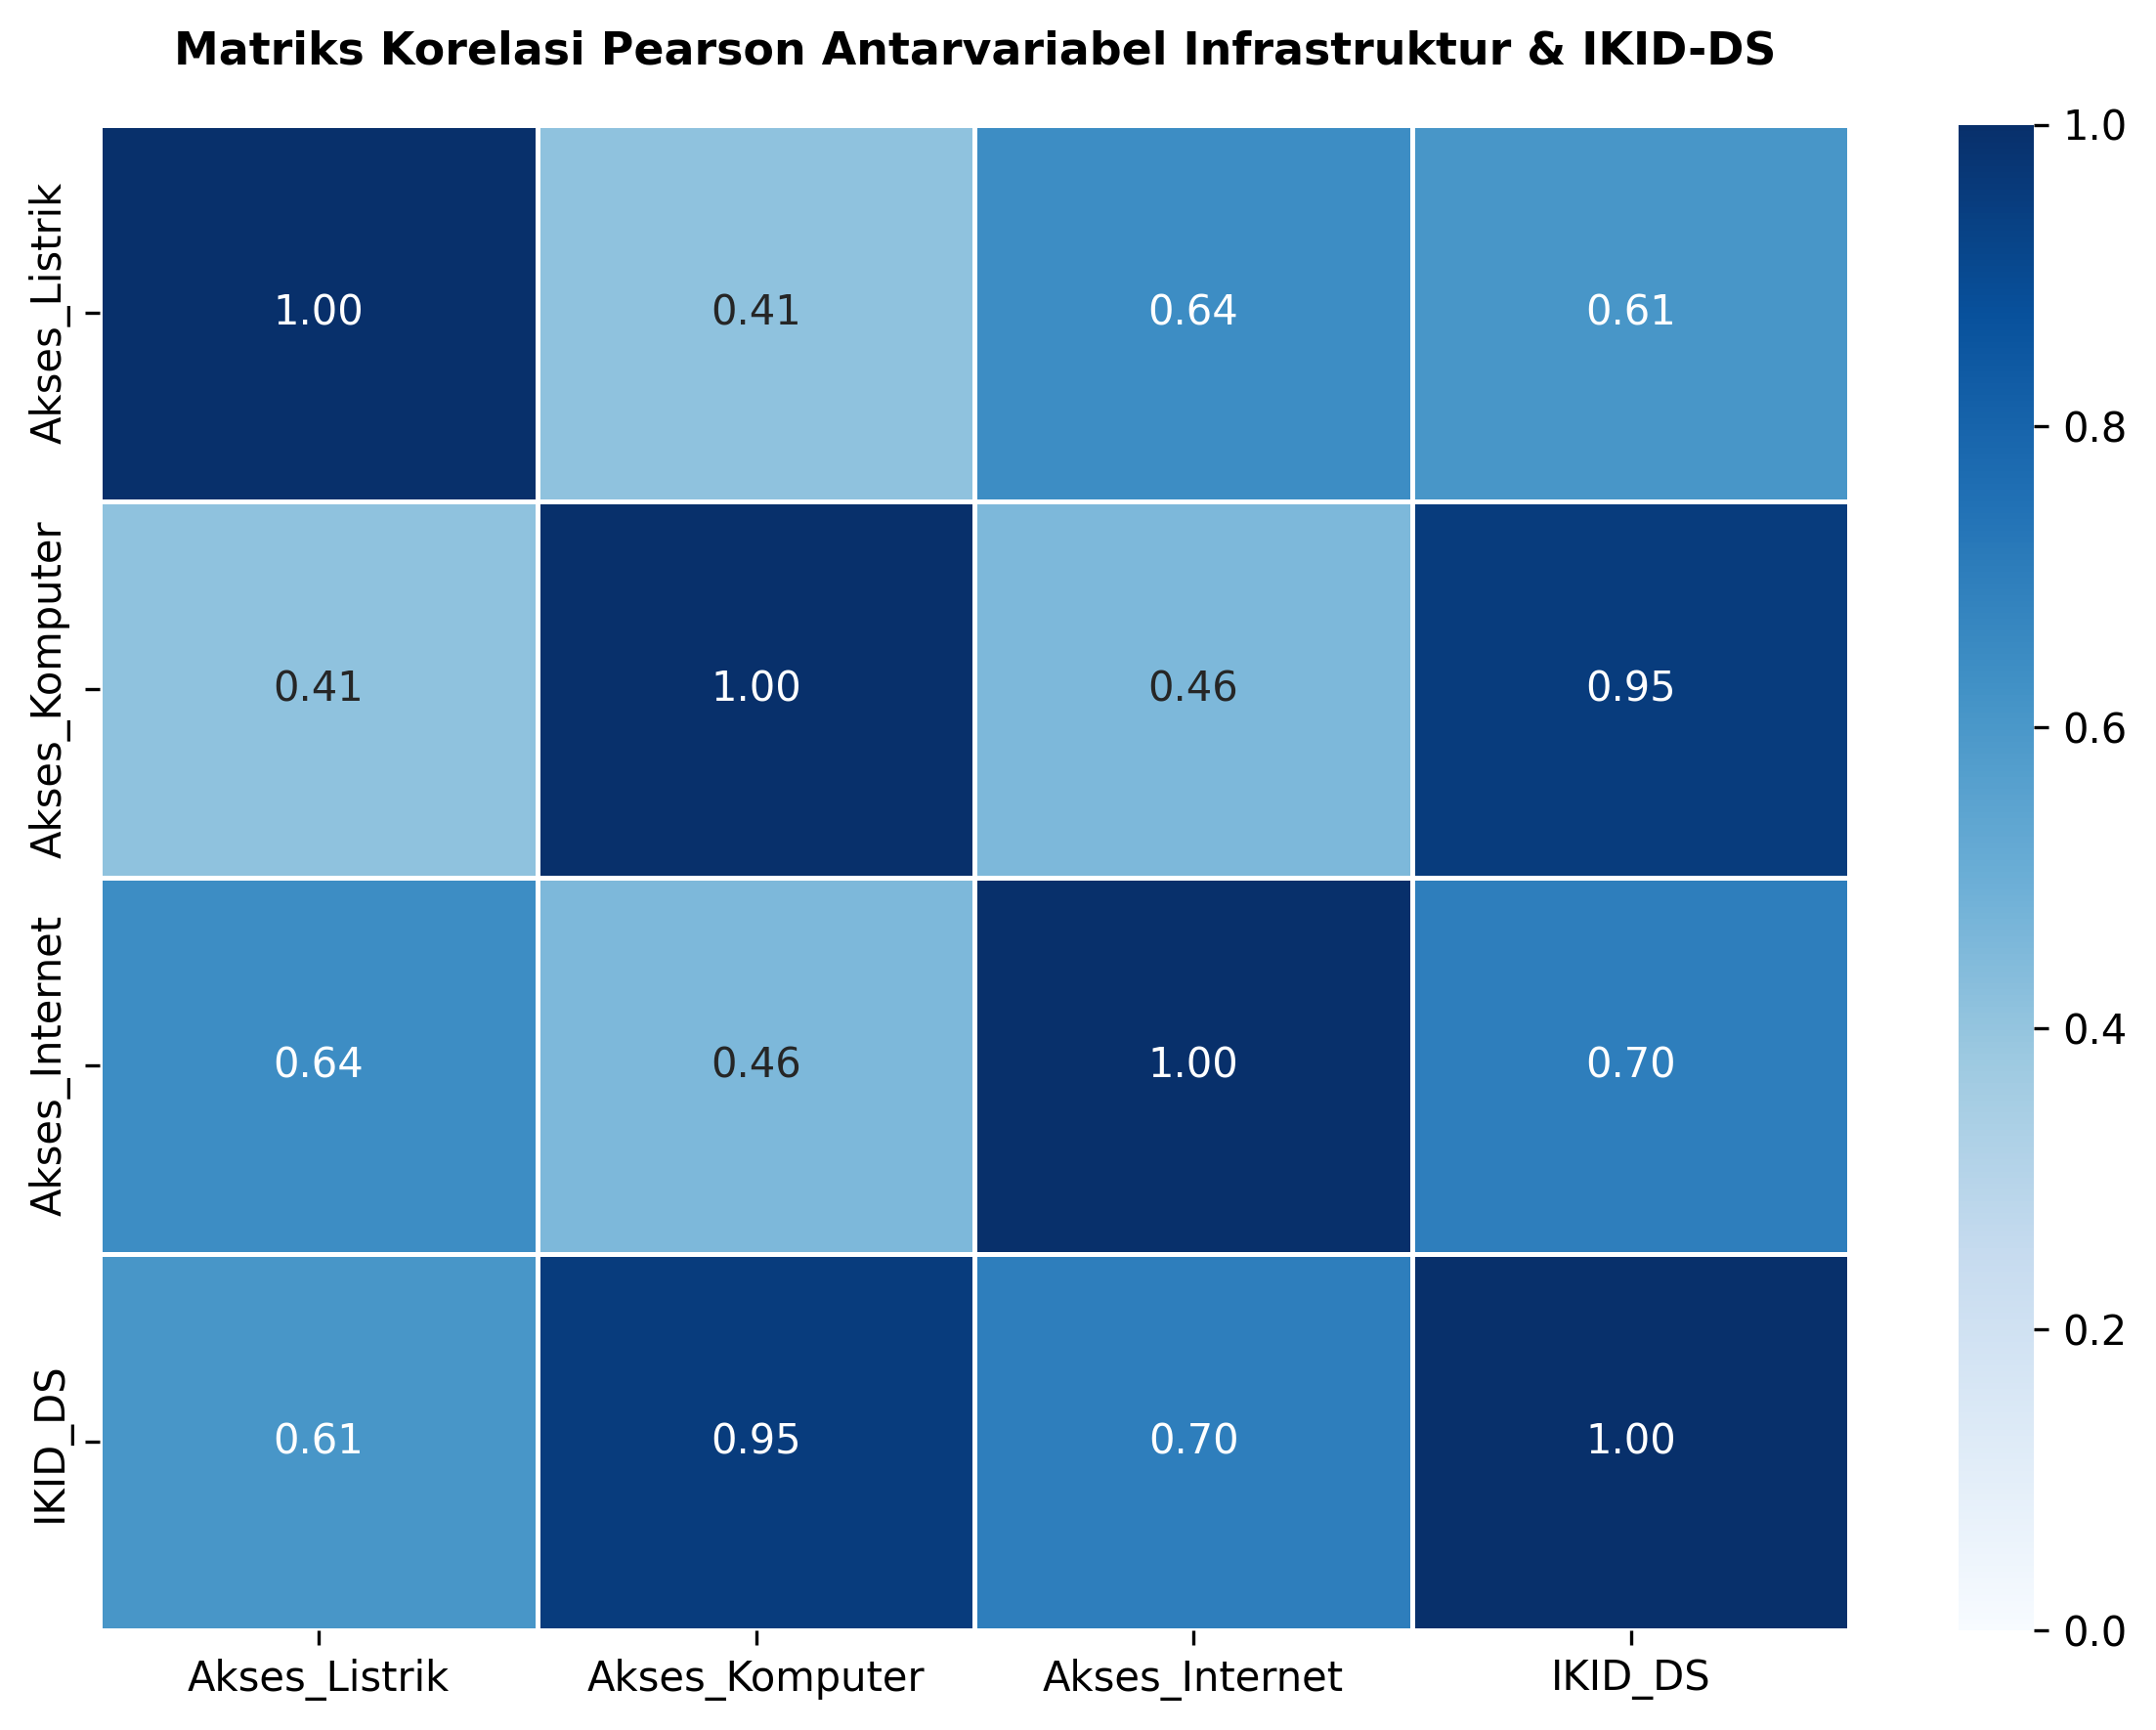

✅ Heatmap korelasi berhasil disimpan sebagai 'Matriks_Korelasi_Pearson.png'!


In [ ]:
# 1. Pastikan pustaka yang dibutuhkan terinstal
!pip install pandas seaborn matplotlib -q

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# 2. LOAD DATASET & PREPROCESSING
# ==========================================
# Sesuaikan nama file dengan file ber-IKID yang ada di panel kiri Google Colab Anda
file_path = "Data_Persentase_2024_2025_IKID_DS_MinMax.xlsx"  # Ganti jika nama file berbeda

try:
  df = pd.read_excel(file_path)
  print("✅ Berhasil memuat dataset di Google Colab.")
except Exception as e:
  print(
      f"❌ Gagal memuat file. Pastikan nama file sudah benar: {e}"
  )
  raise

# Menyesuaikan nama kolom agar seragam
df = df.rename(
    columns={
        "Akses Listrik": "Akses_Listrik",
        "Akses Komputer": "Akses_Komputer",
        "Akses Internet": "Akses_Internet",
        "IKID_DS_MinMax": "IKID_DS",  # Sesuaikan jika nama kolom IKID di Excel Anda berbeda
    }
)

# Memilih variabel numerik yang akan diuji korelasinya
vars_to_test = ["Akses_Listrik", "Akses_Komputer", "Akses_Internet", "IKID_DS"]
df_subset = df[vars_to_test].dropna()

# ==========================================
# 3. MENGHITUNG MATRIKS KORELASI PEARSON
# ==========================================
print("\n" + "=" * 60)
print("MATRIKS KORELASI PEARSON ANTARVARIABEL")
print("=" * 60)
corr_matrix = df_subset.corr(method="pearson").round(4)
print(corr_matrix.to_string())
print("=" * 60 + "\n")

# ==========================================
# 4. VISUALISASI HEATMAP KORELASI
# ==========================================
print("🎨 Sedang merender heatmap matriks korelasi...")

plt.figure(figsize=(8, 6), dpi=300)
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.8,
    cbar=True,
    vmin=0,
    vmax=1,
)

plt.title(
    "Matriks Korelasi Pearson Antarvariabel Infrastruktur & IKID-DS",
    fontsize=11,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()

# Menyimpan hasil gambar heatmap
output_corr_img = "Matriks_Korelasi_Pearson.png"
plt.savefig(
    output_corr_img, dpi=300, bbox_inches="tight", facecolor="white", edgecolor="none"
)
plt.show()

print(f"✅ Heatmap korelasi berhasil disimpan sebagai '{output_corr_img}'!")

In [ ]:
# 1. Pastikan pustaka yang dibutuhkan tersedia
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# 2. Load Dataset
file_path = "Data_Persentase_2024_2025_dengan_IKID_DS.xlsx"
df = pd.read_excel(file_path)

# 3. Transformasi Target Kontinu menjadi Kategori (Rendah, Sedang, Tinggi)
df["Kategori_IKID"] = pd.qcut(
    df["IKID_DS"], q=3, labels=["Rendah", "Sedang", "Tinggi"]
)

# 4. Menentukan Variabel Fitur (X) dan Target (y)
X = df[["Akses Listrik", "Akses Komputer", "Akses Internet"]]
y = df["Kategori_IKID"]

# 5. Membagi Data Training dan Testing (80% latih, 20% uji)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Membangun dan Melatih Model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 7. Evaluasi Model
y_pred = rf_model.predict(X_test)
print(f"🎯 Akurasi Model Random Forest: {accuracy_score(y_test, y_pred):.4f}\n")
print("📊 Laporan Klasifikasi:")
print(classification_report(y_test, y_pred))

# 8. Menampilkan Tingkat Kepentingan Fitur (Feature Importance)
print("=" * 40)
print("🔍 TINGKAT KEPENTINGAN FITUR (FEATURE IMPORTANCE)")
print("=" * 40)
importances = rf_model.feature_importances_
for col, imp in zip(X.columns, importances):
  print(f"- {col}: {imp:.4f}")

🎯 Akurasi Model Random Forest: 0.9180

📊 Laporan Klasifikasi:
              precision    recall  f1-score   support

      Rendah       1.00      1.00      1.00        19
      Sedang       0.88      0.92      0.90        24
      Tinggi       0.88      0.83      0.86        18

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.92      0.92      0.92        61

🔍 TINGKAT KEPENTINGAN FITUR (FEATURE IMPORTANCE)
- Akses Listrik: 0.2476
- Akses Komputer: 0.4108
- Akses Internet: 0.3416


✅ Berhasil memuat dataset untuk Random Forest.

🎯 AKURASI MODEL RANDOM FOREST: 91.80%

📊 Laporan Klasifikasi (Classification Report):
              precision    recall  f1-score   support

      Rendah       1.00      1.00      1.00        19
      Sedang       0.88      0.92      0.90        24
      Tinggi       0.88      0.83      0.86        18

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.92      0.92      0.92        61


🔍 TINGKAT KEPENTINGAN FITUR (FEATURE IMPORTANCE)
         Fitur  Tingkat_Kepentingan
Akses Komputer             0.410776
Akses Internet             0.341620
 Akses Listrik             0.247604


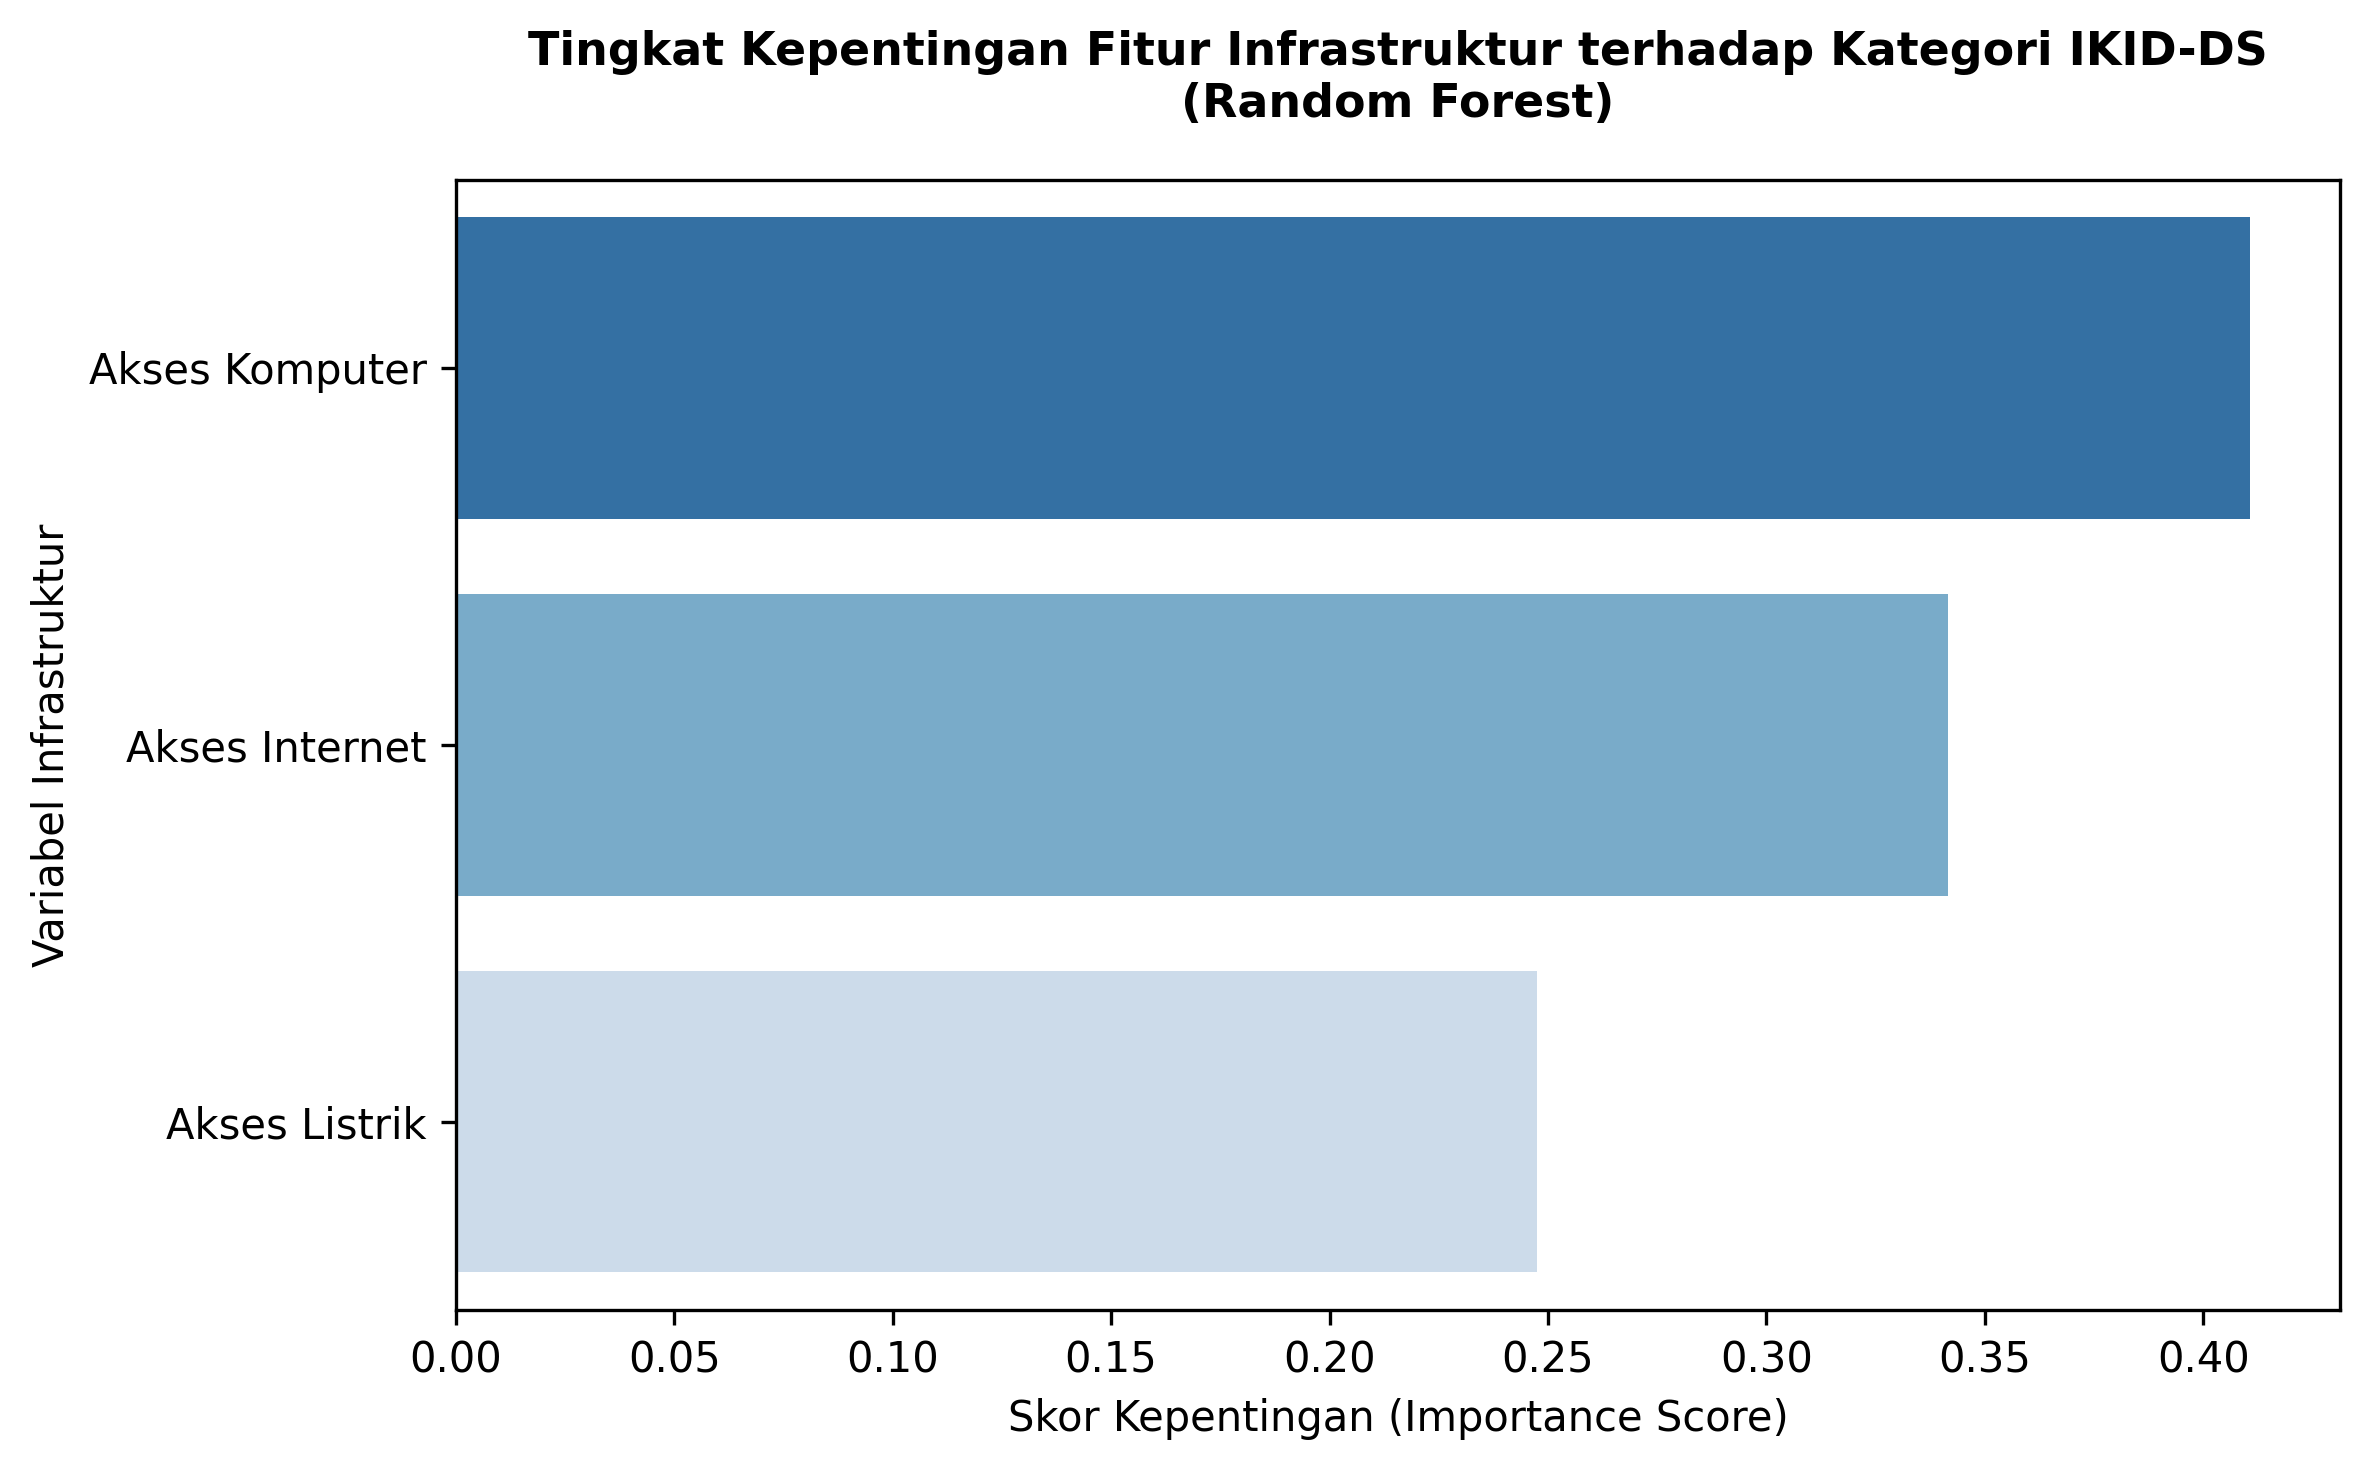


✅ Grafik visualisasi berhasil disimpan sebagai 'Random_Forest_Feature_Importance.png' dan siap dimasukkan ke laporan Serkom!


In [ ]:
# 1. Pastikan pustaka yang dibutuhkan tersedia
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# ==========================================
# 2. LOAD DATASET & PREPROCESSING
# ==========================================
# Pastikan nama file sesuai dengan yang ada di panel Files Google Colab Anda
file_path = "Data_Persentase_2024_2025_dengan_IKID_DS.xlsx"

try:
  df = pd.read_excel(file_path)
  print("✅ Berhasil memuat dataset untuk Random Forest.")
except Exception as e:
  print(f"❌ Gagal memuat file: {e}")
  raise

# 3. Transformasi Target Kontinu (IKID_DS) menjadi Kategori (Rendah, Sedang, Tinggi)
df["Kategori_IKID"] = pd.qcut(
    df["IKID_DS"], q=3, labels=["Rendah", "Sedang", "Tinggi"]
)

# 4. Menentukan Variabel Fitur (X) dan Target (y)
X = df[["Akses Listrik", "Akses Komputer", "Akses Internet"]]
y = df["Kategori_IKID"]

# 5. Membagi Data Training dan Testing (80% latih, 20% uji)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 6. TRAINING MODEL RANDOM FOREST
# ==========================================
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Prediksi & Evaluasi
y_pred = rf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 50)
print(f"🎯 AKURASI MODEL RANDOM FOREST: {accuracy * 100:.2f}%")
print("=" * 50)
print("\n📊 Laporan Klasifikasi (Classification Report):")
print(classification_report(y_test, y_pred))

# ==========================================
# 7. MENGEKSTRAK FEATURE IMPORTANCE
# ==========================================
feature_names = X.columns
importances = rf_model.feature_importances_

df_importance = pd.DataFrame(
    {"Fitur": feature_names, "Tingkat_Kepentingan": importances}
).sort_values(by="Tingkat_Kepentingan", ascending=False)

print("\n" + "=" * 50)
print("🔍 TINGKAT KEPENTINGAN FITUR (FEATURE IMPORTANCE)")
print("=" * 50)
print(df_importance.to_string(index=False))

# ==========================================
# 8. VISUALISASI GRAFIK FEATURE IMPORTANCE
# ==========================================
plt.figure(figsize=(8, 5), dpi=300)
sns.barplot(
    x="Tingkat_Kepentingan",
    y="Fitur",
    data=df_importance,
    palette="Blues_r",
    hue="Fitur",
    legend=False,
)

plt.title(
    "Tingkat Kepentingan Fitur Infrastruktur terhadap Kategori IKID-DS\n(Random"
    " Forest)",
    fontsize=11,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Skor Kepentingan (Importance Score)", fontsize=10)
plt.ylabel("Variabel Infrastruktur", fontsize=10)
plt.tight_layout()

# Menyimpan gambar grafik
output_rf_img = "Random_Forest_Feature_Importance.png"
plt.savefig(
    output_rf_img, dpi=300, bbox_inches="tight", facecolor="white", edgecolor="none"
)
plt.show()

print(
    f"\n✅ Grafik visualisasi berhasil disimpan sebagai '{output_rf_img}' dan"
    " siap dimasukkan ke laporan Serkom!"
)

✅ Berhasil memuat dataset untuk Decision Tree.

🎯 AKURASI MODEL DECISION TREE: 93.44%

📊 Laporan Klasifikasi (Classification Report):
              precision    recall  f1-score   support

      Rendah       1.00      0.95      0.97        19
      Sedang       0.88      0.96      0.92        24
      Tinggi       0.94      0.89      0.91        18

    accuracy                           0.93        61
   macro avg       0.94      0.93      0.94        61
weighted avg       0.94      0.93      0.93        61


🎨 Sedang merender diagram struktur Decision Tree...


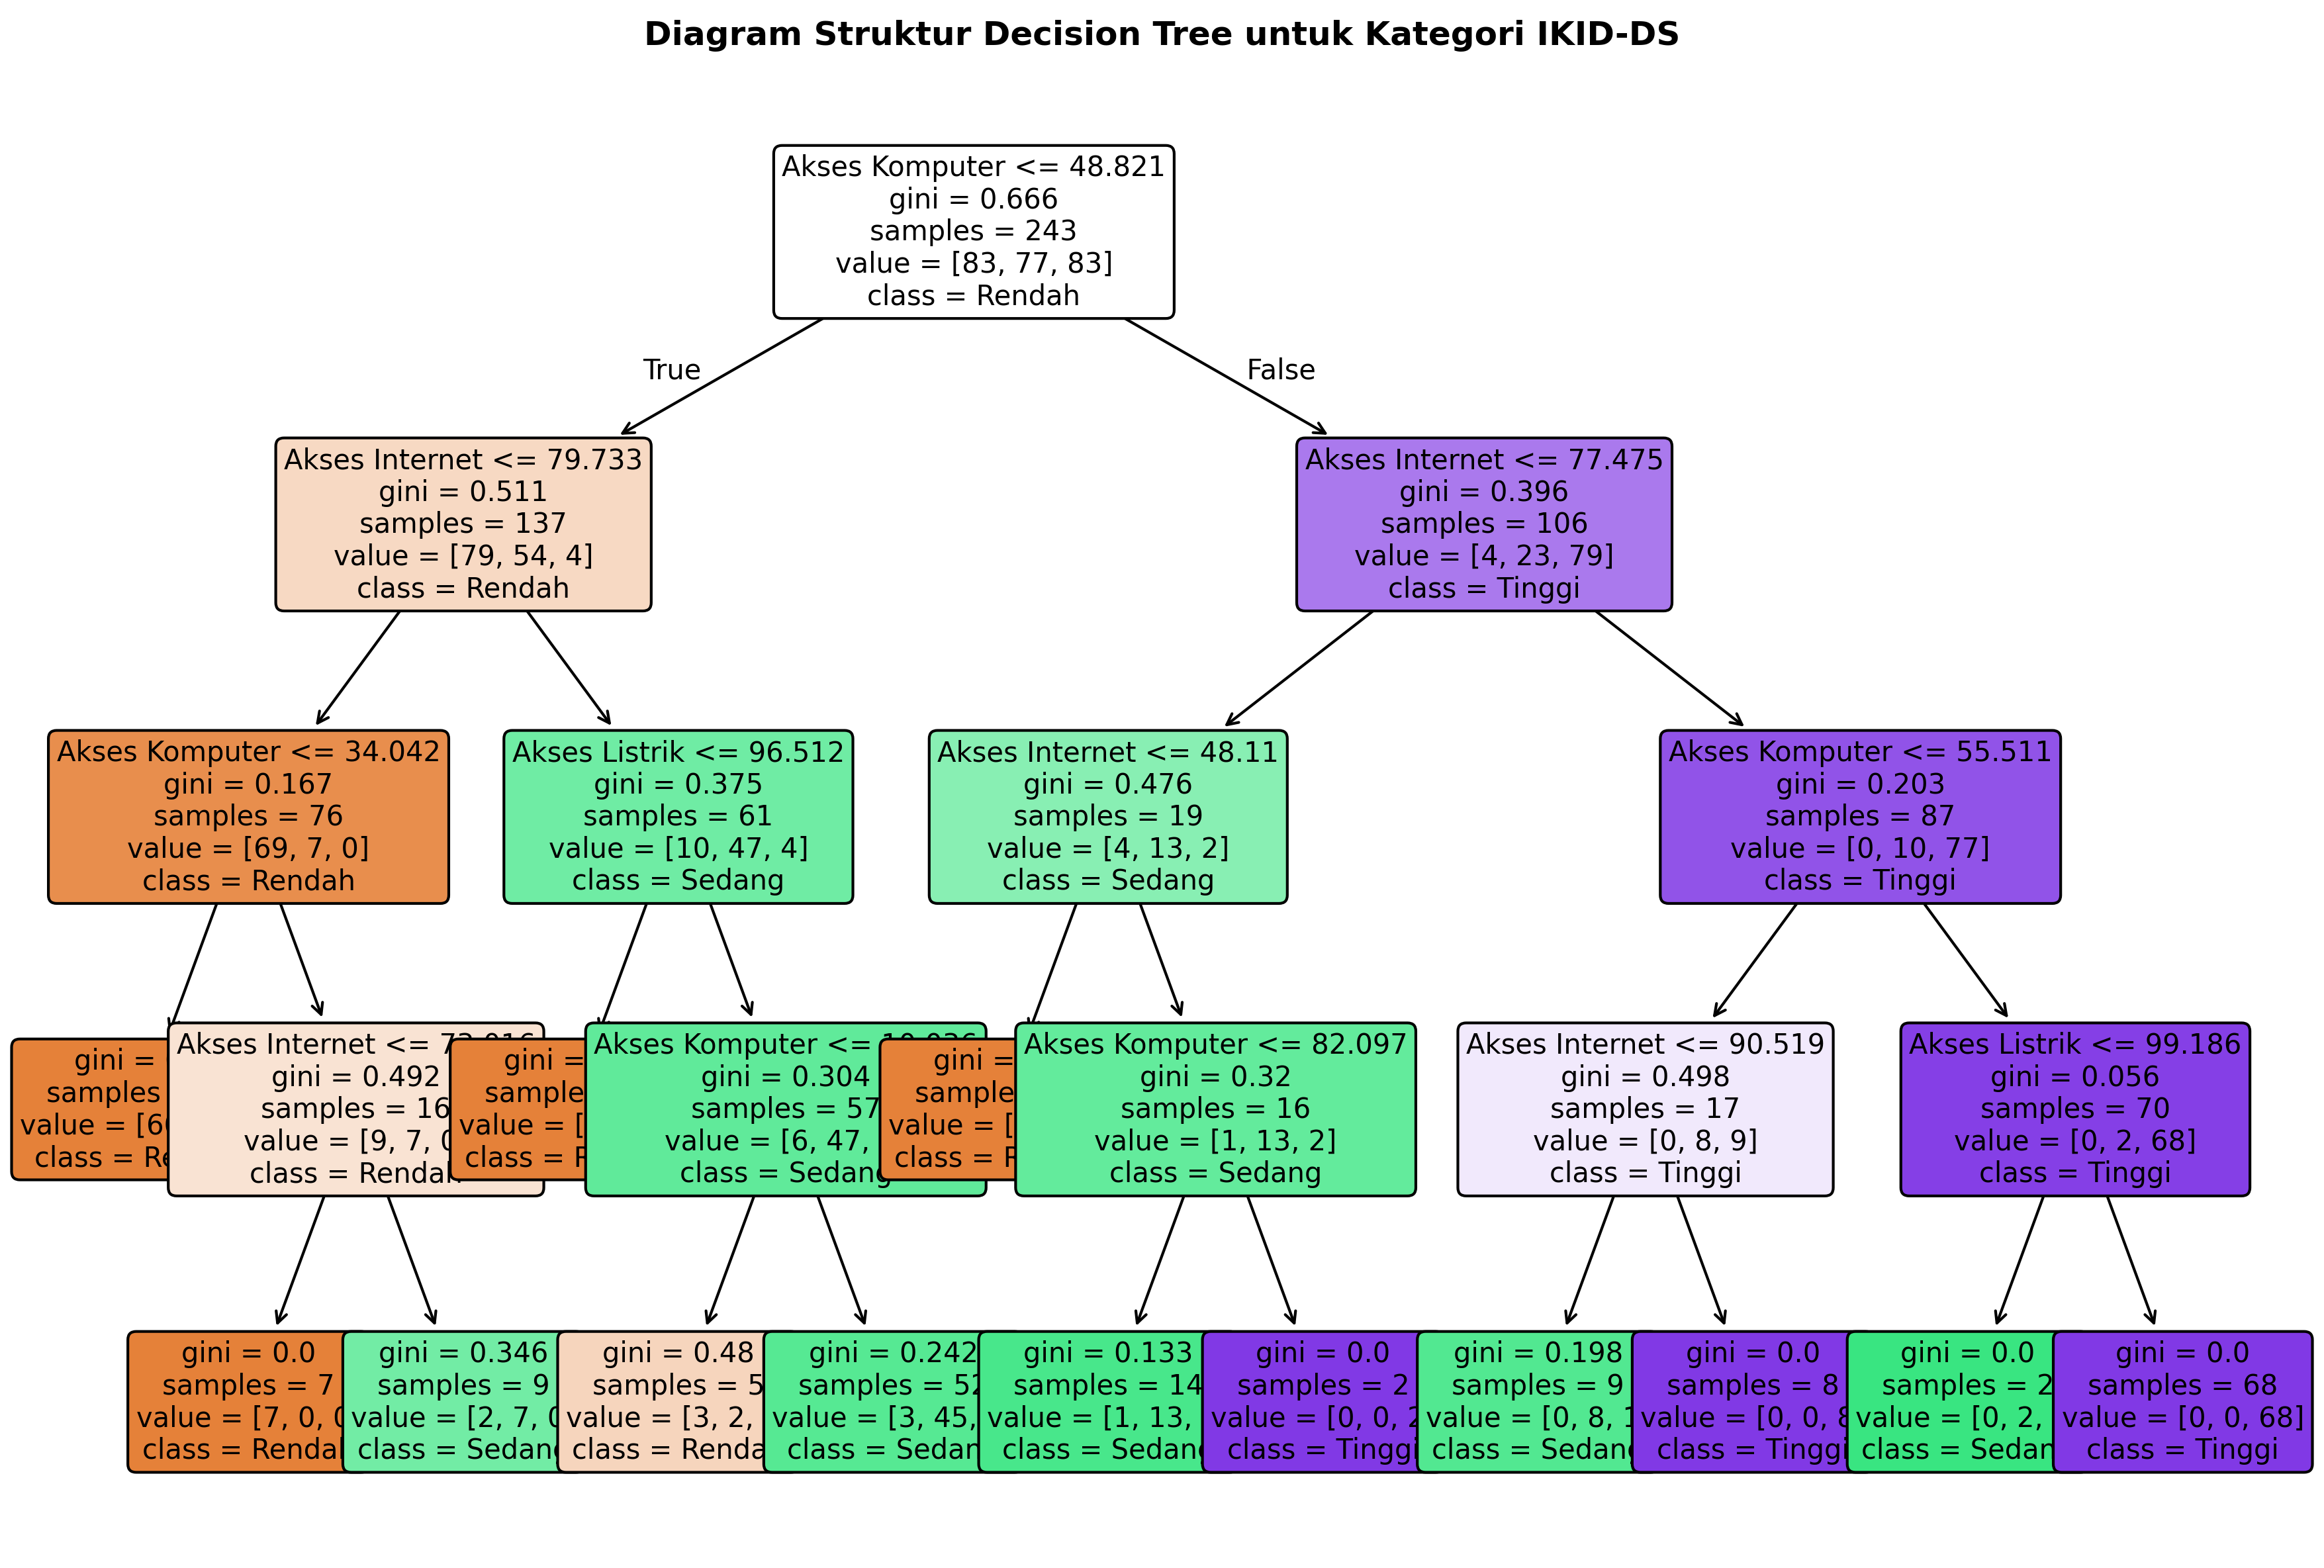


✅ Diagram Decision Tree berhasil disimpan sebagai 'Decision_Tree_Structure.png' dan siap dimasukkan ke laporan Serkom!


In [ ]:
# 1. Pastikan pustaka yang dibutuhkan tersedia
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# ==========================================
# 2. LOAD DATASET & PREPROCESSING
# ==========================================
file_path = "Data_Persentase_2024_2025_dengan_IKID_DS.xlsx"

try:
  df = pd.read_excel(file_path)
  print("✅ Berhasil memuat dataset untuk Decision Tree.")
except Exception as e:
  print(f"❌ Gagal memuat file: {e}")
  raise

# Transformasi Target Kontinu (IKID_DS) menjadi Kategori (Rendah, Sedang, Tinggi)
df["Kategori_IKID"] = pd.qcut(
    df["IKID_DS"], q=3, labels=["Rendah", "Sedang", "Tinggi"]
)

# Menentukan Variabel Fitur (X) dan Target (y)
X = df[["Akses Listrik", "Akses Komputer", "Akses Internet"]]
y = df["Kategori_IKID"]

# Membagi Data Training dan Testing (80% latih, 20% uji)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 3. TRAINING MODEL DECISION TREE
# ==========================================
# max_depth dibatasi agar pohon tidak terlalu besar dan mudah dibaca
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

# Prediksi & Evaluasi
y_pred = dt_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 50)
print(f"🎯 AKURASI MODEL DECISION TREE: {accuracy * 100:.2f}%")
print("=" * 50)
print("\n📊 Laporan Klasifikasi (Classification Report):")
print(classification_report(y_test, y_pred))

# ==========================================
# 4. VISUALISASI STRUKTUR POHON KEPUTUSAN
# ==========================================
print("\n🎨 Sedang merender diagram struktur Decision Tree...")

plt.figure(figsize=(12, 8), dpi=300)
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
)

plt.title(
    "Diagram Struktur Decision Tree untuk Kategori IKID-DS",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()

# Menyimpan gambar visualisasi pohon
output_dt_img = "Decision_Tree_Structure.png"
plt.savefig(
    output_dt_img, dpi=300, bbox_inches="tight", facecolor="white", edgecolor="none"
)
plt.show()

print(
    f"\n✅ Diagram Decision Tree berhasil disimpan sebagai '{output_dt_img}' dan"
    " siap dimasukkan ke laporan Serkom!"
)

In [ ]:
## kode yang kontruksi

In [5]:
import pandas as pd

# Membaca file Excel langsung dari environment Colab
file_name = 'Data_Persentase_2024_2025.xlsx'
df = pd.read_excel(file_name)

# Filter hanya untuk tahun 2024 dan 2025 (pastikan nama kolom sesuai, misal 'Year' atau 'Tahun')
# Jika nama kolomnya masih bahasa Indonesia ('Tahun'), gunakan 'Tahun'.
# Sesuai instruksi untuk menggunakan bahasa Inggris, diasumsikan kolomnya 'Year'.
year_col = 'Year' if 'Year' in df.columns else 'Tahun'
df = df[df[year_col].isin([2024, 2025])]

print(f"Total rows: {len(df)}")
print(f"Years available: {sorted(df[year_col].unique().tolist())}")
print(df.head().to_string(index=False))

Total rows: 304
Years available: [2024, 2025]
      Provinsi  Tahun  Akses Listrik  Akses Komputer  Akses Internet Tingkat Pendidikan
          Aceh   2024      99.830125        9.456399           66.36                 SD
Sumatera Utara   2024      97.005435        7.137729           67.46                 SD
Sumatera Barat   2024      99.358060        5.920114           68.26                 SD
          Riau   2024      97.876802        8.807339           76.64                 SD
         Jambi   2024      99.188312        6.858766           76.22                 SD


In [6]:
import pandas as pd

# Membaca file Excel dari environment Colab Anda
file_name = 'Data_Persentase_2024_2025.xlsx'  # Sesuaikan dengan nama file yang aktif
df = pd.read_excel(file_name)

df = df.rename(columns={
    'Provinsi': 'Province',
    'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access'
})

# Filter only 2024 and 2025
df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']

print("=== Mean per Year (before fix) ===")
print(df.groupby('Year')[numeric_cols].mean().round(2))
print()

mask_2025 = df['Year'] == 2025

scale_map = {
    'Electricity Access': None,   # auto-detect
    'Internet Access':    None,   # auto-detect
    'Computer Access':    100,    # force multiply by 100
}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]

    if factor is None:
        if col_2025.max() <= 1:
            factor = 100
        elif col_2025.max() <= 10:
            factor = 10
        else:
            print(f"'{col}' 2025: no conversion needed (max={col_2025.max():.2f})")
            continue

    df.loc[mask_2025, col] = col_2025 * factor
    print(f"Converted '{col}' for 2025: × {factor} (max before={col_2025.max():.2f})")

print()
print("=== Mean per Year (after fix) ===")
print(df.groupby('Year')[numeric_cols].mean().round(2))

print()
print("=== 2024 & 2025 Data (all rows) ===")
print(df.to_string(index=False))

=== Mean per Year (before fix) ===
      Electricity Access  Internet Access  Computer Access
Year                                                      
2024               98.23            76.60            46.33
2025                1.63             0.84             0.89

'Electricity Access' 2025: no conversion needed (max=100.00)
Converted 'Internet Access' for 2025: × 100 (max before=1.00)
Converted 'Computer Access' for 2025: × 100 (max before=75.00)

=== Mean per Year (after fix) ===
      Electricity Access  Internet Access  Computer Access
Year                                                      
2024               98.23            76.60            46.33
2025                1.63            84.11            89.01

=== 2024 & 2025 Data (all rows) ===
                 Province  Year  Electricity Access  Computer Access  Internet Access Education Level
                     Aceh  2024           99.830125         9.456399        66.360000              SD
           Sumatera Utara  202

In [7]:
!pip install factor-analyzer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor-analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=b6bf66a816fe42cdebba5c4006ac07c6cc7b4d24da11e0c466999ea563c72fd0
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor-analyzer


In [10]:
import pandas as pd

sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province',
    'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access'
})

# Filter only 2024 and 2025
df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']

print("=== Mean per Year (before fix) ===")
print(df.groupby('Year')[numeric_cols].mean().round(4))
print()

mask_2025 = df['Year'] == 2025

# Paksa kali 100 untuk semua kolom numerik di tahun 2025 karena datanya dalam bentuk desimal/proporsi (0-1)
for col in numeric_cols:
    old_max = df.loc[mask_2025, col].max()
    df.loc[mask_2025, col] = df.loc[mask_2025, col] * 100
    print(f"Converted '{col}' for 2025: multiplied by 100 (max before={old_max:.4f})")

print()
print("=== Mean per Year (after fix) ===")
print(df.groupby('Year')[numeric_cols].mean().round(2))

print()
print("=== 2024 & 2025 Data (sample rows) ===")
print(df.head(15).to_string(index=False))

=== Mean per Year (before fix) ===
      Electricity Access  Internet Access  Computer Access
Year                                                      
2024             98.2294          76.8014          46.3305
2025              0.9853           0.8410           0.4015

Converted 'Electricity Access' for 2025: multiplied by 100 (max before=1.0000)
Converted 'Internet Access' for 2025: multiplied by 100 (max before=1.0000)
Converted 'Computer Access' for 2025: multiplied by 100 (max before=0.7500)

=== Mean per Year (after fix) ===
      Electricity Access  Internet Access  Computer Access
Year                                                      
2024               98.23             76.8            46.33
2025               98.53             84.1            40.15

=== 2024 & 2025 Data (sample rows) ===
                   Province  Year  Electricity Access  Computer Access  Internet Access Education Level
                      Aceh   2024               99.83             9.46            

In [11]:
# Menyimpan data yang sudah diperbaiki ke file CSV baru
df.to_csv('Data_Persentase_2024_2025_Fixed.csv', index=False)
print("Data berhasil disimpan ke file baru: Data_Persentase_2024_2025_Fixed.csv")

# Atau jika ingin disimpan dalam format Excel
df.to_excel('Data_Persentase_2024_2025_Fixed.xlsx', index=False)
print("Data berhasil disimpan ke file baru: Data_Persentase_2024_2025_Fixed.xlsx")

Data berhasil disimpan ke file baru: Data_Persentase_2024_2025_Fixed.csv
Data berhasil disimpan ke file baru: Data_Persentase_2024_2025_Fixed.xlsx


In [12]:
import pandas as pd
import warnings
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

warnings.filterwarnings("ignore")

# 1. GENERATE & SAVE CLEANED DATA FIRST
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province',
    'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access'
})

# Filter only 2024 and 2025
df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025

# Paksa kali 100 untuk seluruh kolom numerik di tahun 2025 karena skalanya di bawah 1 (proporsi)
for col in numeric_cols:
    old_max = df.loc[mask_2025, col].max()
    df.loc[mask_2025, col] = df.loc[mask_2025, col] * 100
    print(f"Converted '{col}' for 2025: multiplied by 100 (max before={old_max:.4f})")

# Save cleaned data to a new file
cleaned_filename = 'data_2024_2025_cleaned.csv'
df.to_csv(cleaned_filename, index=False)
print(f"\nCleaned data successfully saved to: {cleaned_filename}")

print("Available columns:", df.columns.tolist())
print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")
print("-" * 50)

# 2. DATA PREPARATION FOR ASSUMPTION TESTS
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()
print(f"Data focused on 3 main variables. Total rows and columns: {df_subset.shape}")
print("-" * 50)

# 3. BARTLETT'S TEST OF SPHERICITY
print("=== 1. Bartlett's Test of Sphericity Results ===")
chi_square_value, p_value = calculate_bartlett_sphericity(df_subset)
print(f"Chi-Square Value : {chi_square_value:.4f}")
print(f"P-value          : {p_value:.4e}")

if p_value < 0.05:
    print("Conclusion       : P-value < 0.05 -> Variables are correlated (TEST PASSED).")
else:
    print("Conclusion       : P-value >= 0.05 -> Variables are NOT correlated (TEST FAILED).")

print("\n" + "-" * 50 + "\n")

# 4. KAISER-MEYER-OLKIN (KMO) TEST
print("=== 2. Kaiser-Meyer-Olkin (KMO) Test Results ===")
kmo_all, kmo_model = calculate_kmo(df_subset)
print(f"KMO Score (Overall) : {kmo_model:.4f}")

if kmo_model >= 0.5:
    print("Conclusion          : KMO >= 0.5 -> Sample is adequate (TEST PASSED).")
    print("-> DATA IS ELIGIBLE to proceed to dimensionality reduction (PCA).")
else:
    print("Conclusion          : KMO < 0.5 -> Sample is inadequate (TEST FAILED).")

Converted 'Electricity Access' for 2025: multiplied by 100 (max before=1.0000)
Converted 'Internet Access' for 2025: multiplied by 100 (max before=1.0000)
Converted 'Computer Access' for 2025: multiplied by 100 (max before=0.7500)

Cleaned data successfully saved to: data_2024_2025_cleaned.csv
Available columns: ['Province', 'Year', 'Electricity Access', 'Computer Access', 'Internet Access', 'Education Level']
Years included: [2024, 2025]
Total rows: 304
--------------------------------------------------
Data focused on 3 main variables. Total rows and columns: (304, 3)
--------------------------------------------------
=== 1. Bartlett's Test of Sphericity Results ===
Chi-Square Value : 276.3681
P-value          : 1.2932e-59
Conclusion       : P-value < 0.05 -> Variables are correlated (TEST PASSED).

--------------------------------------------------

=== 2. Kaiser-Meyer-Olkin (KMO) Test Results ===
KMO Score (Overall) : 0.6482
Conclusion          : KMO >= 0.5 -> Sample is adequate (T

In [14]:
# 1. LOAD DATA FROM GOOGLE SHEETS
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

# 2. RENAME COLUMNS TO ENGLISH
df = df.rename(columns={
    'Provinsi': 'Province',
    'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

# 3. FILTER 2024 & 2025 ONLY
df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

# 4. FIX 2025 SCALE
numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025

scale_map = {
    'Electricity Access': None,
    'Internet Access':    None,
    'Computer Access':    100,
}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]

    if factor is None:
        if col_2025.max() <= 1:
            factor = 100
        elif col_2025.max() <= 10:
            factor = 10
        else:
            continue

    df.loc[mask_2025, col] = col_2025 * factor

print("Scale fix applied for Year 2025.")
print(f"Years included: {sorted(df['Year'].unique().tolist())}")

# 5. SELECT 3 MAIN VARIABLES
selected = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected].select_dtypes(include=['number']).dropna()

# 6. MIN-MAX NORMALIZATION (0–100)
scaler = MinMaxScaler(feature_range=(0, 100))
df_norm = pd.DataFrame(scaler.fit_transform(df_subset),
                        columns=selected, index=df_subset.index)

# 7. REATTACH PROVINCE & YEAR COLUMNS
if 'Province' in df.columns:
    df_norm.insert(0, 'Province', df.loc[df_subset.index, 'Province'])
if 'Year' in df.columns:
    df_norm.insert(1, 'Year', df.loc[df_subset.index, 'Year'])

# 8. EXPORT
df_norm.to_csv('normalized_ikidds.csv', index=False)
print(df_norm.head())

Scale fix applied for Year 2025.
Years included: [2024, 2025]
           Province  Year  Electricity Access  Internet Access  \
0             Aceh   2024           99.526989        59.523810   
1   Sumatera Utara   2024           91.680579        60.714286   
2   Sumatera Barat   2024           98.219254        61.904762   
3             Riau   2024           94.101280        72.619048   
4            Jambi   2024           97.746244        71.428571   

   Computer Access  
0         7.075575  
1         4.534502  
2         3.198248  
3         6.363636  
4         4.227820  


Years included: [2024, 2025]
Total rows: 304


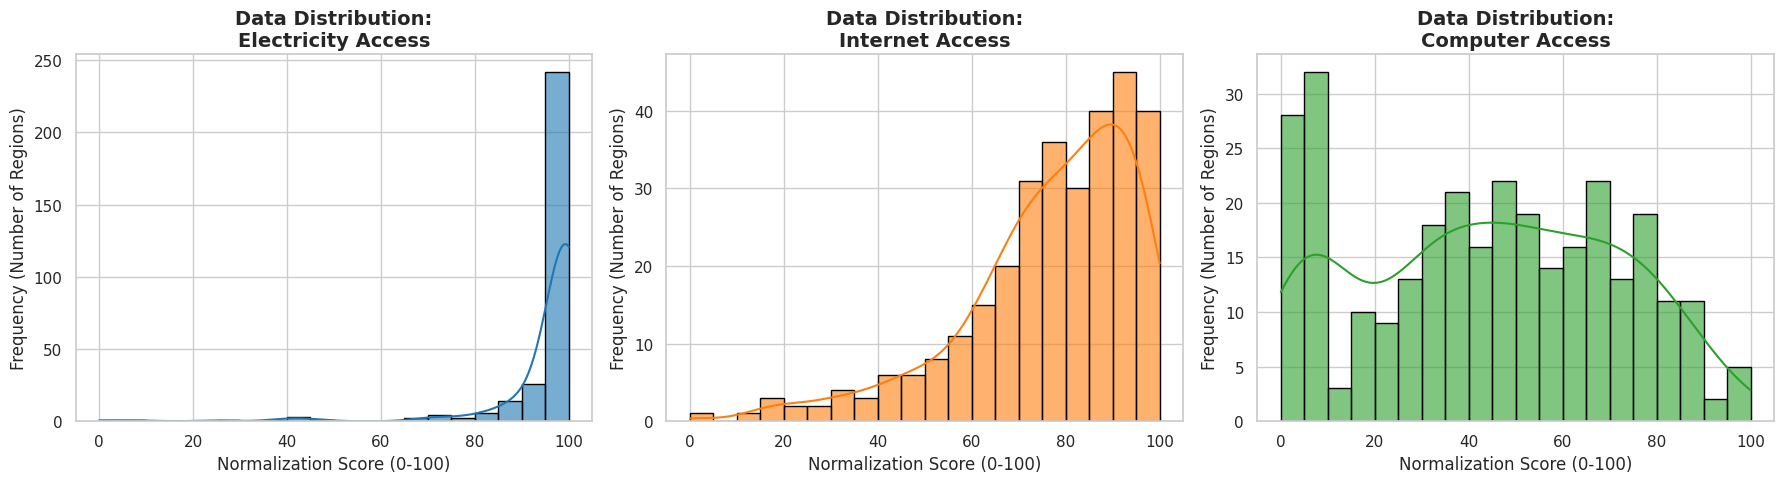

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# 1. LOAD CLEANED DATA (already scaled & filtered)
df = pd.read_csv('data_2024_2025_cleaned.csv')

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")

# 2. SELECT 3 MAIN VARIABLES & NORMALIZE
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
df_norm = pd.DataFrame(scaler.fit_transform(df_subset),
                       columns=selected_columns, index=df_subset.index)

if 'Province' in df.columns:
    df_norm.insert(0, 'Province', df.loc[df_subset.index, 'Province'])

# 3. PLOT HISTOGRAM + KDE
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, col in enumerate(selected_columns):
    sns.histplot(
        df_norm[col],
        bins=20,
        kde=True,
        color=colors[i],
        ax=axes[i],
        edgecolor='black',
        alpha=0.6
    )
    axes[i].set_title(f'Data Distribution:\n{col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Normalization Score (0-100)', fontsize=12)
    axes[i].set_ylabel('Frequency (Number of Regions)', fontsize=12)

plt.tight_layout()
plt.show()

Years included: [2024, 2025]
Total rows: 304


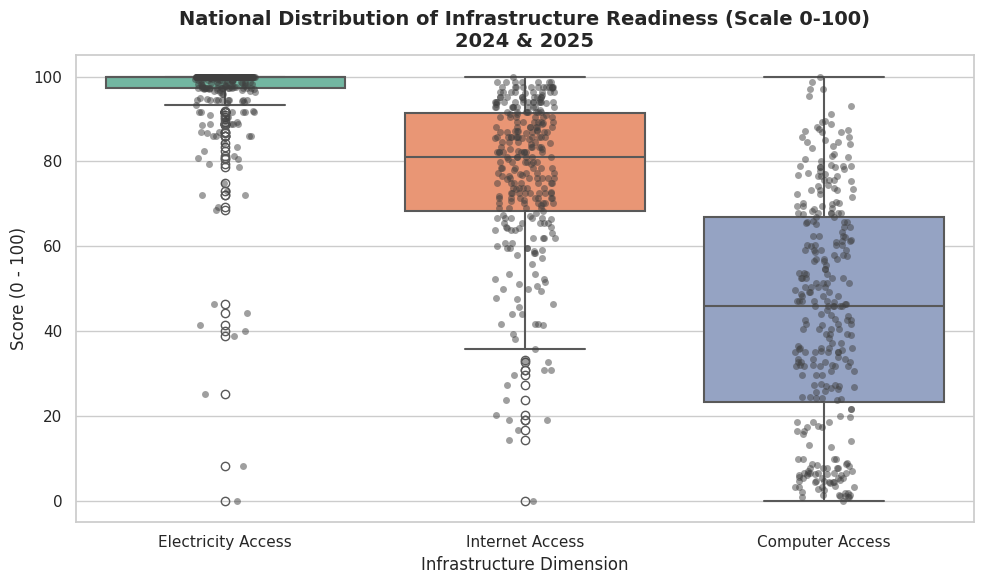

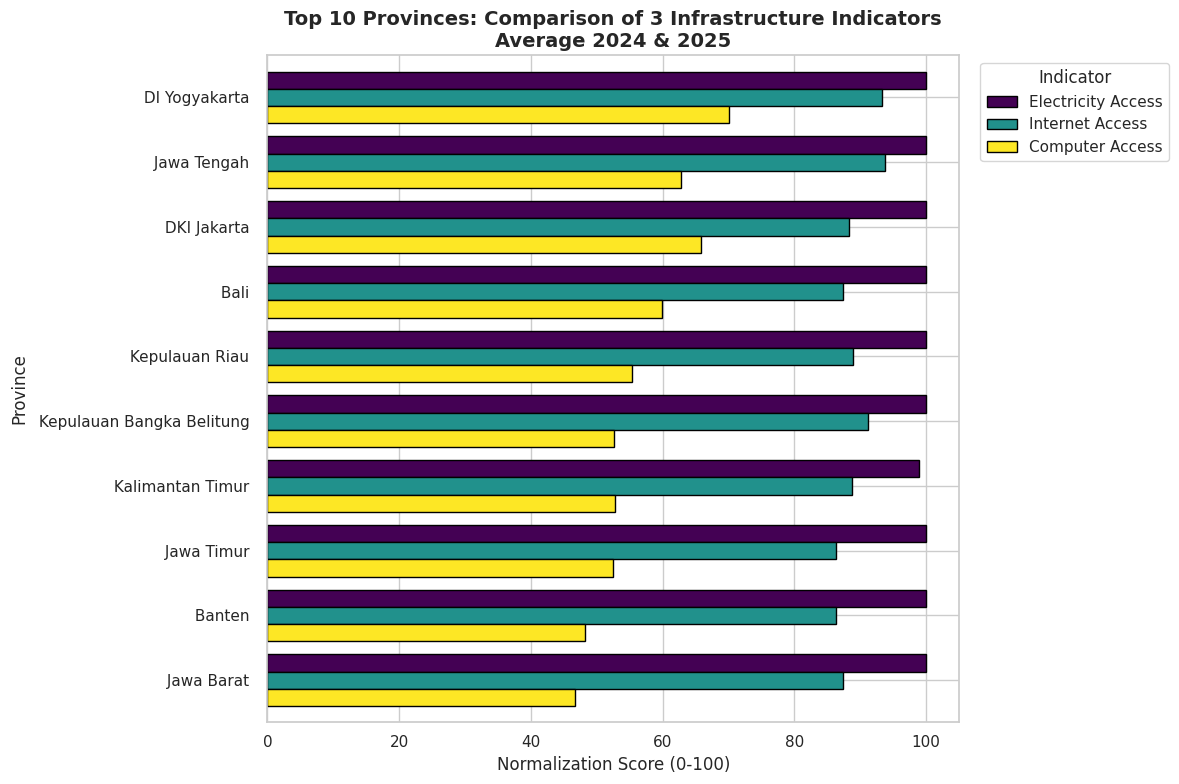

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# 1. LOAD CLEANED DATA (already scaled & filtered)
df = pd.read_csv('data_2024_2025_cleaned.csv')

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")

# 2. SELECT 3 MAIN VARIABLES & NORMALIZE
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
df_norm = pd.DataFrame(scaler.fit_transform(df_subset),
                       columns=selected_columns, index=df_subset.index)

if 'Province' in df.columns:
    df_norm.insert(0, 'Province', df.loc[df_subset.index, 'Province'])
if 'Year' in df.columns:
    df_norm.insert(1, 'Year', df.loc[df_subset.index, 'Year'])

sns.set_theme(style="whitegrid")

# =====================================================================
# VISUALIZATION 1: NATIONAL DISTRIBUTION OF INDICATORS (BOXPLOT)
# =====================================================================
plt.figure(figsize=(10, 6))

df_melted = df_norm.melt(
    id_vars=['Province', 'Year'],
    value_vars=selected_columns,
    var_name='Indicator',
    value_name='Normalization Score (0-100)'
)

sns.boxplot(
    x='Indicator',
    y='Normalization Score (0-100)',
    data=df_melted,
    palette="Set2",
    linewidth=1.5
)

sns.stripplot(
    x='Indicator',
    y='Normalization Score (0-100)',
    data=df_melted,
    color=".25",
    alpha=0.5,
    jitter=True
)

plt.title('National Distribution of Infrastructure Readiness (Scale 0-100)\n2024 & 2025', fontsize=14, fontweight='bold')
plt.xlabel('Infrastructure Dimension', fontsize=12)
plt.ylabel('Score (0 - 100)', fontsize=12)
plt.tight_layout()
plt.show()


# =====================================================================
# VISUALIZATION 2: TOP 10 PROVINCES COMPARISON (BAR CHART)
# Average per province across years to avoid duplicates
# =====================================================================
df_avg = df_norm.groupby('Province')[selected_columns].mean().reset_index()
df_avg['Average'] = df_avg[selected_columns].mean(axis=1)

df_top10 = df_avg.sort_values(by='Average', ascending=False).head(10)
df_top10_plot = df_top10.set_index('Province')[selected_columns]

ax = df_top10_plot.plot(
    kind='barh',
    figsize=(12, 8),
    colormap='viridis',
    edgecolor='black',
    width=0.8
)

plt.title('Top 10 Provinces: Comparison of 3 Infrastructure Indicators\nAverage 2024 & 2025', fontsize=14, fontweight='bold')
plt.xlabel('Normalization Score (0-100)', fontsize=12)
plt.ylabel('Province', fontsize=12)

plt.gca().invert_yaxis()

plt.legend(title='Indicator', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
import numpy as np
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

# 1. LOAD DATA FROM GOOGLE SHEETS
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

# 2. RENAME COLUMNS TO ENGLISH
df = df.rename(columns={
    'Provinsi': 'Province',
    'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

# 3. FILTER 2024 & 2025 ONLY
df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

# 4. FIX 2025 SCALE
numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025

scale_map = {
    'Electricity Access': None,
    'Internet Access':    None,
    'Computer Access':    100,
}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]

    if factor is None:
        if col_2025.max() <= 1:
            factor = 100
        elif col_2025.max() <= 10:
            factor = 10
        else:
            continue

    df.loc[mask_2025, col] = col_2025 * factor

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print("Scale fix applied for Year 2025.")
print("-" * 50)

# 5. SELECT 3 MAIN VARIABLES
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

# 6. MIN-MAX NORMALIZATION (SCALE 0–100)
scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

# 7. APPLY PCA FOR OBJECTIVE WEIGHTING & INDEX CALCULATION
pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

explained_variance_ratio = pca.explained_variance_ratio_[0]
print(f"Explained Variance Ratio (PC1): {explained_variance_ratio * 100:.2f}%")

loadings = pca.components_[0]
weights_objective = np.abs(loadings) / np.sum(np.abs(loadings))

print("\n=== Objective Weight of Each Variable from PCA ===")
for col, w in zip(selected_columns, weights_objective):
    print(f"- {col}: {w:.4f} ({w*100:.2f}%)")

print("-" * 50)

# 8. CONSTRUCT COMPOSITE INDEX SCORE (IKID-DS)
score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

# 9. MERGE IKID-DS SCORE WITH FULL DATA
df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# 10. EXPORT TO CSV FILE
output_filename = 'ikid_ds_pca_final_output.csv'
df_full_output.to_csv(output_filename, index=False)
print(f"Composite index data successfully saved to: {output_filename}")

# --- GOOGLE COLAB ONLY (Auto-download file) ---
# from google.colab import files
# files.download(output_filename)

print("\n=== First 5 Rows of IKID-DS Final Output ===")
print(df_full_output.head())

Years included: [2024, 2025]
Scale fix applied for Year 2025.
--------------------------------------------------
Explained Variance Ratio (PC1): 73.98%

=== Objective Weight of Each Variable from PCA ===
- Electricity Access: 0.1596 (15.96%)
- Internet Access: 0.2903 (29.03%)
- Computer Access: 0.5502 (55.02%)
--------------------------------------------------
Composite index data successfully saved to: ikid_ds_pca_final_output.csv

=== First 5 Rows of IKID-DS Final Output ===
           Province  Year  Electricity Access  Computer Access  \
0             Aceh   2024               99.83             9.46   
1   Sumatera Utara   2024               97.01             7.14   
2   Sumatera Barat   2024               99.36             5.92   
3             Riau   2024               97.88             8.81   
4            Jambi   2024               99.19             6.86   

   Internet Access Education Level  IKID_DS_Score  
0             66.0              SD      37.285424  
1             67.

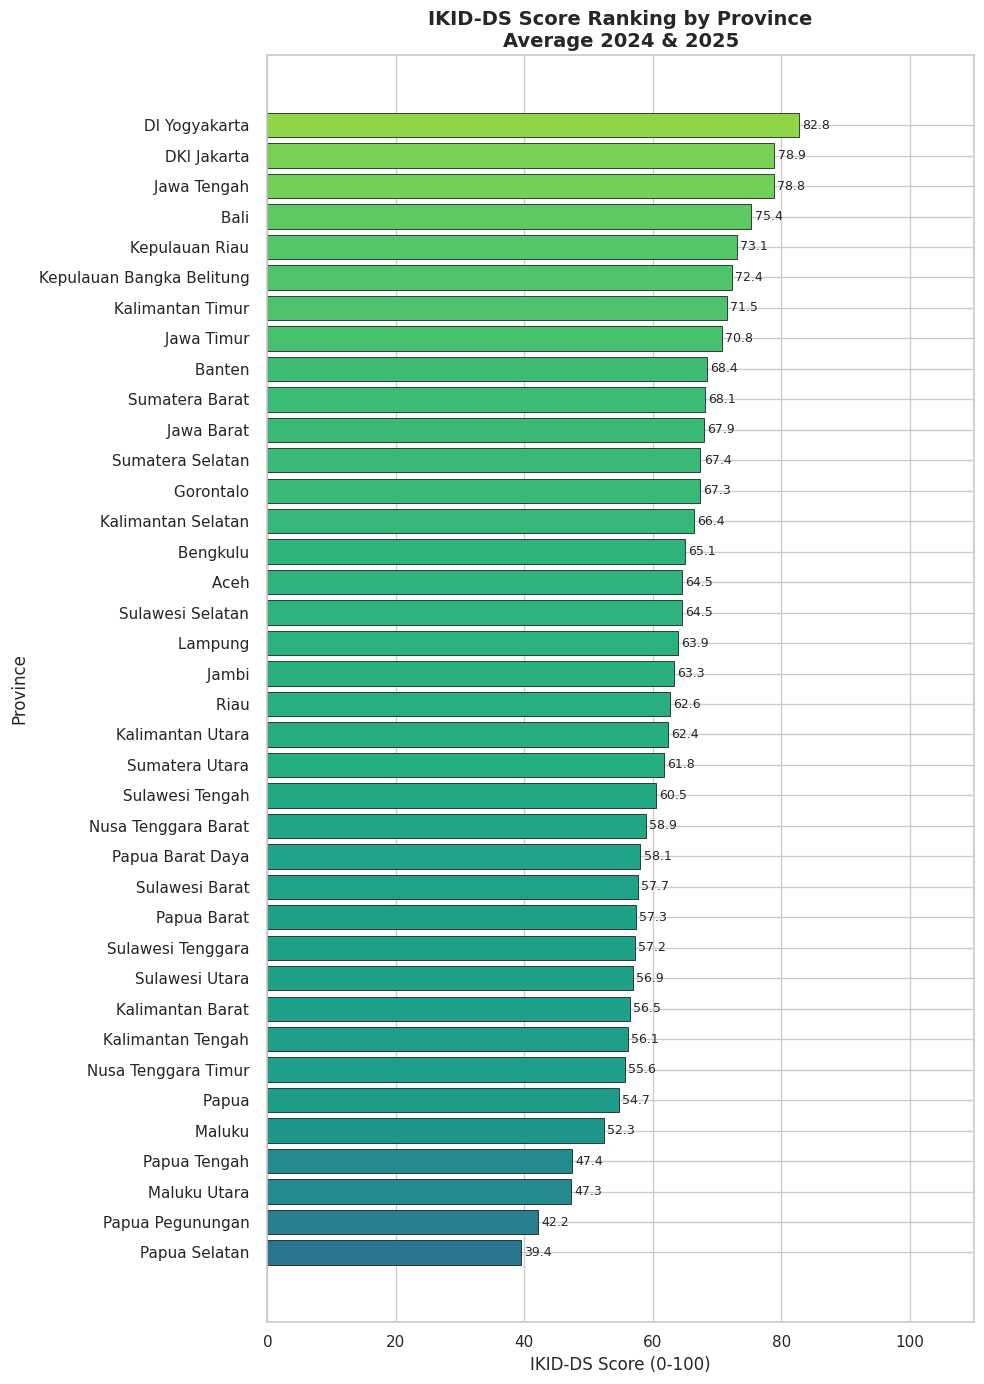

In [19]:
#Visualiasasikan
# ============================================================
# IKID-DS VISUALIZATION 1: BAR CHART — PROVINCE RANKING
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

# LOAD & PREPARE DATA
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province', 'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025
scale_map = {'Electricity Access': None, 'Internet Access': None, 'Computer Access': 100}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]
    if factor is None:
        if col_2025.max() <= 1: factor = 100
        elif col_2025.max() <= 10: factor = 10
        else: continue
    df.loc[mask_2025, col] = col_2025 * factor

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# Average per province across years
df_avg = df_full_output.groupby('Province')['IKID_DS_Score'].mean().reset_index()
df_avg = df_avg.sort_values('IKID_DS_Score', ascending=True)

# PLOT
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 14))

bars = ax.barh(
    df_avg['Province'], df_avg['IKID_DS_Score'],
    color=plt.cm.viridis(df_avg['IKID_DS_Score'] / 100),
    edgecolor='black', linewidth=0.5
)

# Add value labels
for bar, val in zip(bars, df_avg['IKID_DS_Score']):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}', va='center', fontsize=9)

ax.set_title('IKID-DS Score Ranking by Province\nAverage 2024 & 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('IKID-DS Score (0-100)', fontsize=12)
ax.set_ylabel('Province', fontsize=12)
ax.set_xlim(0, 110)
plt.tight_layout()
plt.show()

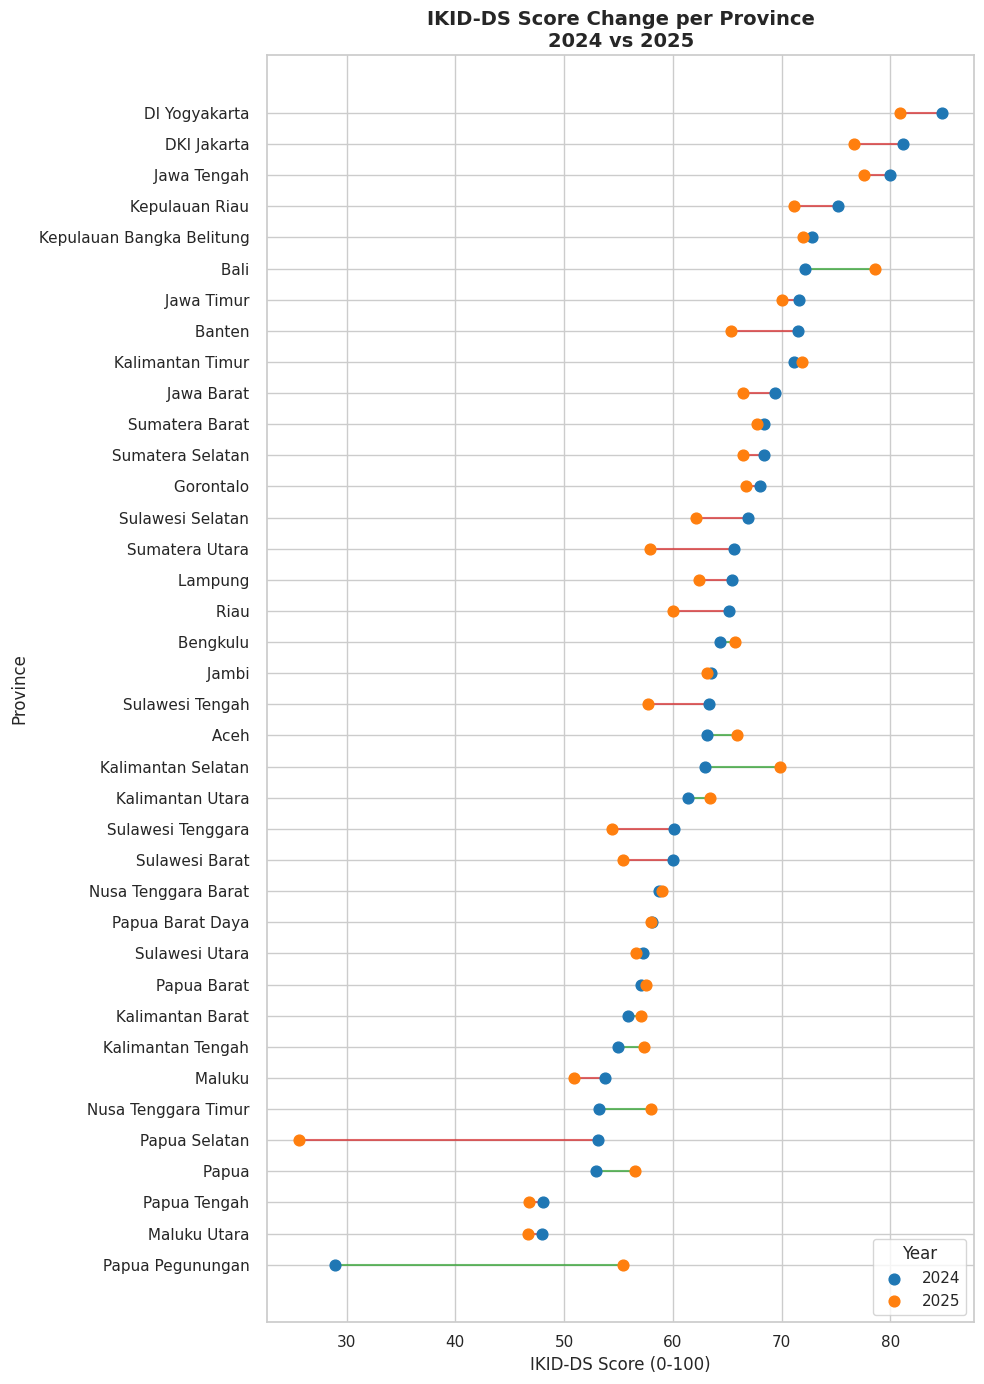


=== Provinces with Biggest Increase ===
             Province  Score_2024  Score_2025    Change
    Papua Pegunungan    28.949294   55.393887 26.444593
  Kalimantan Selatan    62.979252   69.878171  6.898919
                Bali    72.150022   78.553659  6.403637
 Nusa Tenggara Timur    53.250241   57.978588  4.728347
               Papua    52.893984   56.498097  3.604114

=== Provinces with Biggest Decrease ===
           Province  Score_2024  Score_2025     Change
     Papua Selatan    53.137373   25.673533 -27.463839
    Sumatera Utara    65.651107   57.930988  -7.720119
            Banten    71.523000   65.339364  -6.183637
 Sulawesi Tenggara    60.065515   54.368100  -5.697416
   Sulawesi Tengah    63.306469   57.705025  -5.601443


In [20]:
# ============================================================
# IKID-DS VISUALIZATION 2: DUMBBELL CHART — 2024 VS 2025
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

# LOAD & PREPARE DATA
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province', 'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025
scale_map = {'Electricity Access': None, 'Internet Access': None, 'Computer Access': 100}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]
    if factor is None:
        if col_2025.max() <= 1: factor = 100
        elif col_2025.max() <= 10: factor = 10
        else: continue
    df.loc[mask_2025, col] = col_2025 * factor

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# Pivot per year
df_pivot = df_full_output.pivot_table(
    index='Province', columns='Year', values='IKID_DS_Score'
).dropna().reset_index()
df_pivot.columns = ['Province', 'Score_2024', 'Score_2025']
df_pivot['Change'] = df_pivot['Score_2025'] - df_pivot['Score_2024']
df_pivot = df_pivot.sort_values('Score_2024', ascending=True)

# PLOT
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 14))

for _, row in df_pivot.iterrows():
    color = '#2ca02c' if row['Change'] >= 0 else '#d62728'
    ax.plot([row['Score_2024'], row['Score_2025']],
            [row['Province'], row['Province']],
            color=color, linewidth=1.5, alpha=0.7)

ax.scatter(df_pivot['Score_2024'], df_pivot['Province'],
           color='#1f77b4', zorder=5, s=60, label='2024')
ax.scatter(df_pivot['Score_2025'], df_pivot['Province'],
           color='#ff7f0e', zorder=5, s=60, label='2025')

ax.set_title('IKID-DS Score Change per Province\n2024 vs 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('IKID-DS Score (0-100)', fontsize=12)
ax.set_ylabel('Province', fontsize=12)
ax.legend(title='Year', loc='lower right')
plt.tight_layout()
plt.show()

print("\n=== Provinces with Biggest Increase ===")
print(df_pivot.sort_values('Change', ascending=False)[['Province', 'Score_2024', 'Score_2025', 'Change']].head(5).to_string(index=False))
print("\n=== Provinces with Biggest Decrease ===")
print(df_pivot.sort_values('Change')[['Province', 'Score_2024', 'Score_2025', 'Change']].head(5).to_string(index=False))

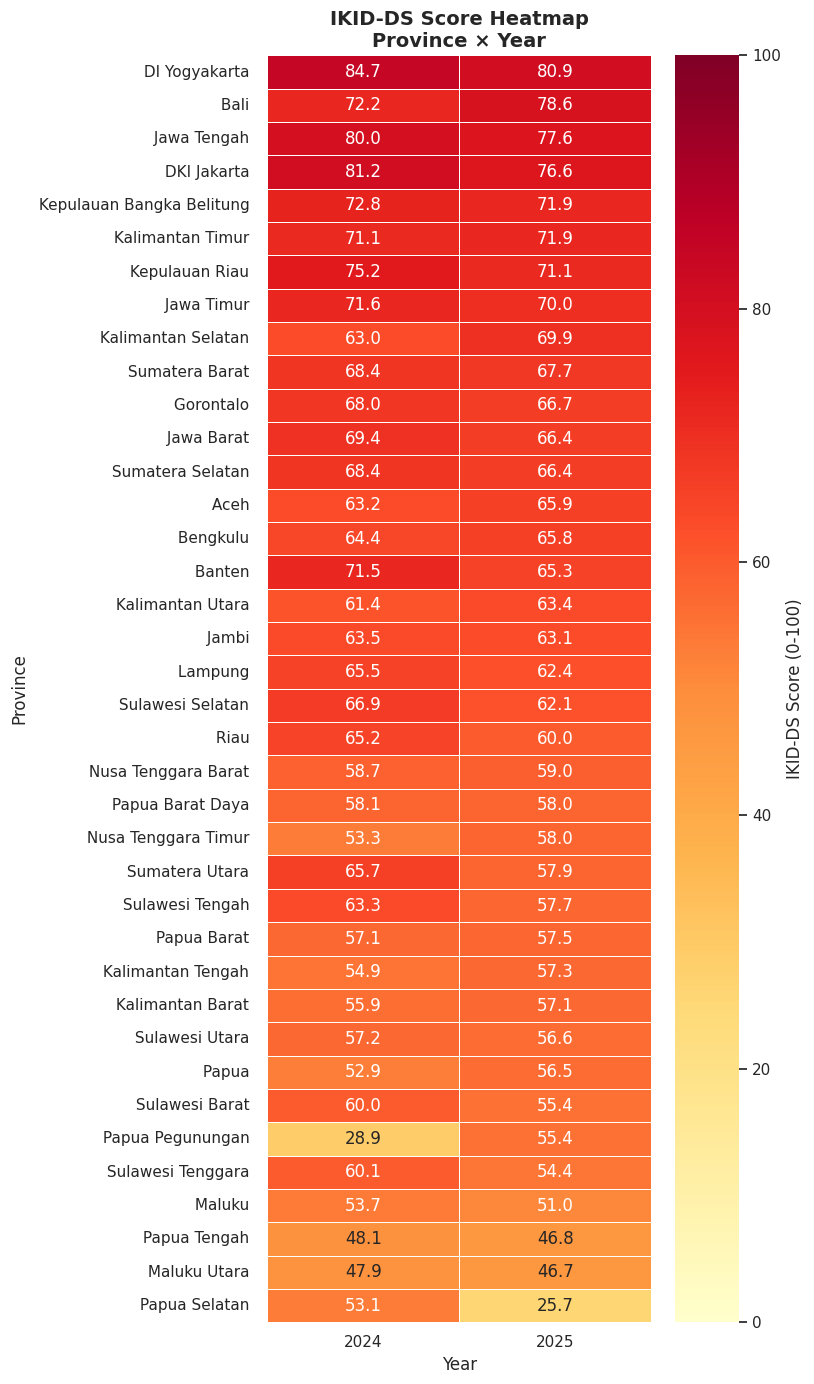

In [21]:
# ============================================================
# IKID-DS VISUALIZATION 3: HEATMAP — PROVINCE × YEAR
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

# LOAD & PREPARE DATA
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province', 'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025
scale_map = {'Electricity Access': None, 'Internet Access': None, 'Computer Access': 100}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]
    if factor is None:
        if col_2025.max() <= 1: factor = 100
        elif col_2025.max() <= 10: factor = 10
        else: continue
    df.loc[mask_2025, col] = col_2025 * factor

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# Pivot for heatmap
df_pivot = df_full_output.pivot_table(
    index='Province', columns='Year', values='IKID_DS_Score'
)
df_pivot = df_pivot.sort_values(by=df_pivot.columns[-1], ascending=False)

# PLOT
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(8, 14))

sns.heatmap(
    df_pivot, annot=True, fmt='.1f',
    cmap='YlOrRd', vmin=0, vmax=100,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'IKID-DS Score (0-100)'},
    ax=ax
)

ax.set_title('IKID-DS Score Heatmap\nProvince × Year', fontsize=14, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Province', fontsize=12)
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

# LOAD & PREPARE DATA
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province', 'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025
scale_map = {'Electricity Access': None, 'Internet Access': None, 'Computer Access': 100}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]
    if factor is None:
        if col_2025.max() <= 1: factor = 100
        elif col_2025.max() <= 10: factor = 10
        else: continue
    df.loc[mask_2025, col] = col_2025 * factor

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)
df_scaled = pd.DataFrame(X_scaled, columns=selected_columns, index=df_subset.index)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

df_plot = df_scaled.copy()
df_plot['IKID_DS_Score'] = ikid_ds_scores
df_plot['Year'] = df.loc[df_subset.index, 'Year'].values
df_plot['Province'] = df.loc[df_subset.index, 'Province'].values

# Tampilkan semua data lengkap
df_display = df_plot[['Province', 'Year', 'Electricity Access', 'Internet Access', 'Computer Access', 'IKID_DS_Score']].copy()
df_display = df_display.sort_values(['Year', 'Province']).reset_index(drop=True)

print(f"Total rows: {len(df_display)}")
print(f"Years: {sorted(df_display['Year'].unique().tolist())}")
print()
print(df_display.to_string(index=False))

Total rows: 304
Years: [2024, 2025]

                   Province  Year  Electricity Access  Internet Access  Computer Access  IKID_DS_Score
                      Aceh   2024           99.526989        59.523810         7.075575      37.285424
                      Aceh   2024           99.582638        70.928571        27.097481      51.926311
                      Aceh   2024          100.000000        82.988095        78.806134      84.625788
                      Aceh   2024          100.000000        84.523810        67.754655      78.870982
                      Bali   2024          100.000000        51.190476         4.720701      33.568778
                      Bali   2024          100.000000        93.809524        70.460022      83.144022
                      Bali   2024          100.000000        91.238095        87.426068      91.915315
                      Bali   2024          100.000000        70.238095        77.250821      79.971973
                    Banten   2024   

In [23]:
import pandas as pd
import numpy as np
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

# 1. LOAD CLEANED DATA (already scaled & filtered)
df = pd.read_csv('data_2024_2025_cleaned.csv')

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")
print("-" * 50)

# 2. SELECT 3 MAIN VARIABLES
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

# 3. MIN-MAX NORMALIZATION (SCALE 0–100)
scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

# 4. APPLY PCA FOR OBJECTIVE WEIGHTING & INDEX CALCULATION
pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

explained_variance_ratio = pca.explained_variance_ratio_[0]
print(f"Explained Variance Ratio (PC1): {explained_variance_ratio * 100:.2f}%")

loadings = pca.components_[0]
weights_objective = np.abs(loadings) / np.sum(np.abs(loadings))

print("\n=== Objective Weight of Each Variable from PCA ===")
for col, w in zip(selected_columns, weights_objective):
    print(f"- {col}: {w:.4f} ({w*100:.2f}%)")

print("-" * 50)

# 5. CONSTRUCT COMPOSITE INDEX SCORE (IKID-DS)
score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

# 6. MERGE IKID-DS SCORE WITH FULL DATA
df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# 7. EXPORT TO CSV FILE
output_filename = 'ikid_ds_pca_final_output.csv'
df_full_output.to_csv(output_filename, index=False)
print(f"Composite index data successfully saved to: {output_filename}")

# --- GOOGLE COLAB ONLY (Auto-download file) ---
# from google.colab import files
# files.download(output_filename)

print("\n=== First 5 Rows of IKID-DS Final Output ===")
print(df_full_output.head())

Years included: [2024, 2025]
Total rows: 304
--------------------------------------------------
Explained Variance Ratio (PC1): 73.98%

=== Objective Weight of Each Variable from PCA ===
- Electricity Access: 0.1596 (15.96%)
- Internet Access: 0.2903 (29.03%)
- Computer Access: 0.5502 (55.02%)
--------------------------------------------------
Composite index data successfully saved to: ikid_ds_pca_final_output.csv

=== First 5 Rows of IKID-DS Final Output ===
           Province  Year  Electricity Access  Computer Access  \
0             Aceh   2024               99.83             9.46   
1   Sumatera Utara   2024               97.01             7.14   
2   Sumatera Barat   2024               99.36             5.92   
3             Riau   2024               97.88             8.81   
4            Jambi   2024               99.19             6.86   

   Internet Access Education Level  IKID_DS_Score  
0             66.0              SD      37.285424  
1             67.0              SD

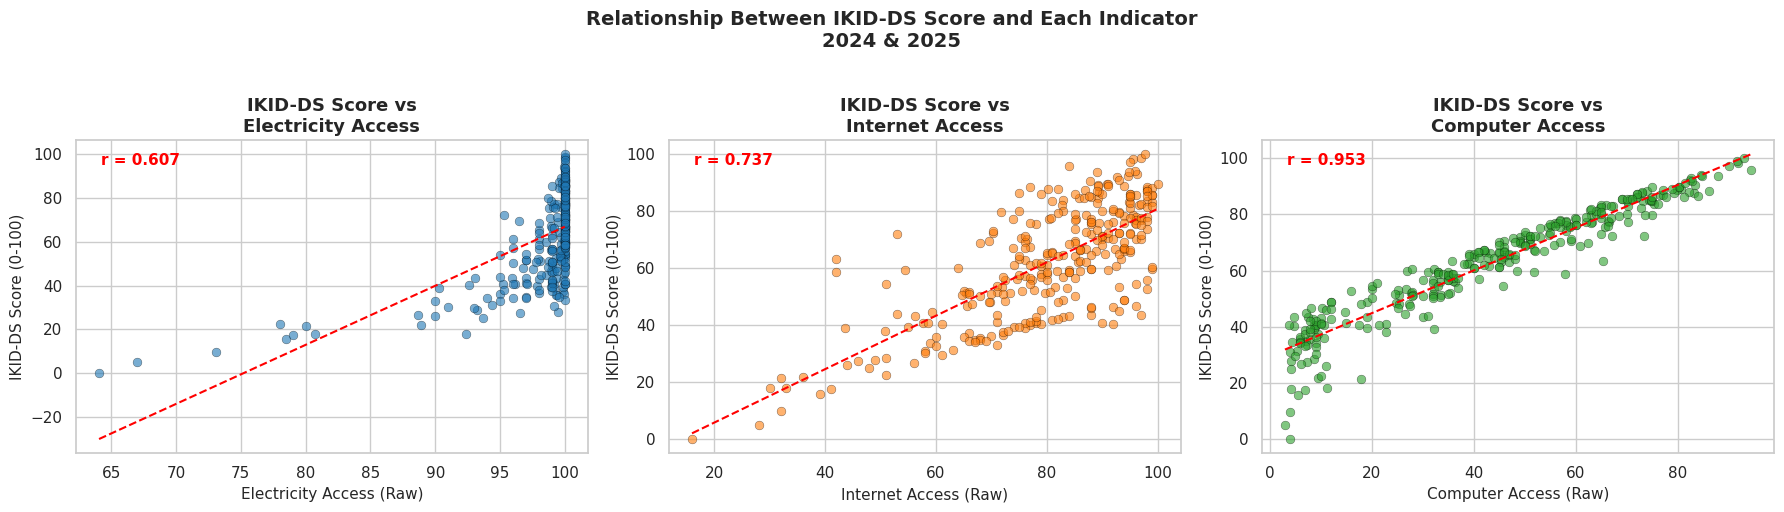

In [24]:
# ============================================================
# IKID-DS VISUALIZATION 4: SCATTER PLOT — SCORE VS INDICATORS
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

# LOAD & PREPARE DATA
sheet_id = "1fuYTjmJf7hZS4HfDT21Ul4bPWiU2j2tEO7rnYI9Nx8g"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"
df = pd.read_csv(url)

df = df.rename(columns={
    'Provinsi': 'Province', 'Tahun': 'Year',
    'Tingkat Pendidikan': 'Education Level',
    'Akses Listrik': 'Electricity Access',
    'Akses Internet': 'Internet Access',
    'Akses Komputer': 'Computer Access',
})

df = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)

numeric_cols = ['Electricity Access', 'Internet Access', 'Computer Access']
mask_2025 = df['Year'] == 2025
scale_map = {'Electricity Access': None, 'Internet Access': None, 'Computer Access': 100}

for col in numeric_cols:
    col_2025 = df.loc[mask_2025, col]
    factor = scale_map[col]
    if factor is None:
        if col_2025.max() <= 1: factor = 100
        elif col_2025.max() <= 10: factor = 10
        else: continue
    df.loc[mask_2025, col] = col_2025 * factor

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# PLOT
sns.set_theme(style="whitegrid")
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(selected_columns):
    axes[i].scatter(
        df_full_output[col], df_full_output['IKID_DS_Score'],
        color=colors[i], alpha=0.6, edgecolor='black', linewidth=0.3, s=40
    )
    # Regression line
    m, b = np.polyfit(df_full_output[col], df_full_output['IKID_DS_Score'], 1)
    x_line = np.linspace(df_full_output[col].min(), df_full_output[col].max(), 100)
    axes[i].plot(x_line, m * x_line + b, color='red', linewidth=1.5, linestyle='--')

    axes[i].set_title(f'IKID-DS Score vs\n{col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel(f'{col} (Raw)', fontsize=11)
    axes[i].set_ylabel('IKID-DS Score (0-100)', fontsize=11)

    corr = df_full_output[col].corr(df_full_output['IKID_DS_Score'])
    axes[i].annotate(f'r = {corr:.3f}', xy=(0.05, 0.92),
                     xycoords='axes fraction', fontsize=11,
                     color='red', fontweight='bold')

plt.suptitle('Relationship Between IKID-DS Score and Each Indicator\n2024 & 2025', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Years included: [2024, 2025]
Total rows: 304


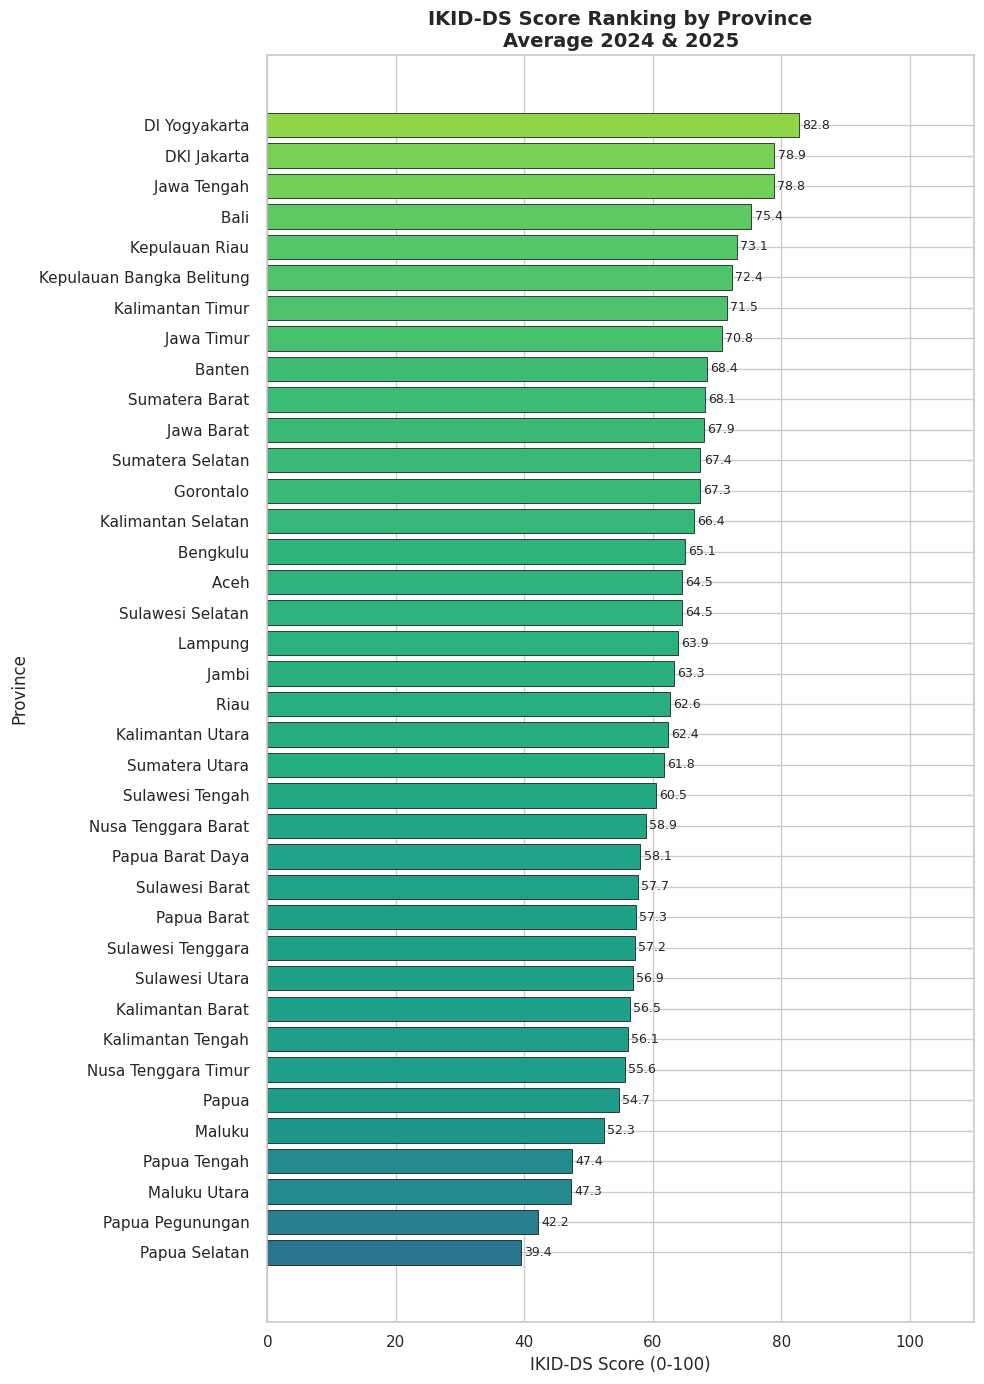

In [25]:
# ============================================================
# IKID-DS VISUALIZATION 1: BAR CHART — PROVINCE RANKING
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

# 1. LOAD CLEANED DATA (already scaled & filtered)
df = pd.read_csv('data_2024_2025_cleaned.csv')

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")

# 2. SELECT 3 MAIN VARIABLES & PCA
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_ds_scores = score_scaler.fit_transform(pc1_scores)

df_full_output = df.loc[df_subset.index].copy()
df_full_output['IKID_DS_Score'] = ikid_ds_scores

# 3. AVERAGE PER PROVINCE ACROSS YEARS
df_avg = df_full_output.groupby('Province')['IKID_DS_Score'].mean().reset_index()
df_avg = df_avg.sort_values('IKID_DS_Score', ascending=True)

# 4. PLOT
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 14))

bars = ax.barh(
    df_avg['Province'], df_avg['IKID_DS_Score'],
    color=plt.cm.viridis(df_avg['IKID_DS_Score'] / 100),
    edgecolor='black', linewidth=0.5
)

for bar, val in zip(bars, df_avg['IKID_DS_Score']):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}', va='center', fontsize=9)

ax.set_title('IKID-DS Score Ranking by Province\nAverage 2024 & 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('IKID-DS Score (0-100)', fontsize=12)
ax.set_ylabel('Province', fontsize=12)
ax.set_xlim(0, 110)
plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np
import warnings
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

# 1. LOAD CLEANED DATA (already scaled & filtered)
df = pd.read_csv('data_2024_2025_cleaned.csv')

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")
print("-" * 50)

# 2. SELECT 3 MAIN VARIABLES
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
df_subset = df[selected_columns].select_dtypes(include=['number']).dropna()

# 3. NORMALIZATION & BASELINE SCORE
scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_subset)

pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)
score_scaler = MinMaxScaler(feature_range=(0, 100))
baseline_scores = score_scaler.fit_transform(pc1_scores).flatten()

# ==========================================
# A. RELIABILITY TEST (CRONBACH'S ALPHA)
# ==========================================
def calculate_cronbach_alpha(data):
    df_cronbach = pd.DataFrame(data)
    k = df_cronbach.shape[1]
    variance_items = df_cronbach.var(ddof=1)
    total_variance = df_cronbach.sum(axis=1).var(ddof=1)
    alpha = (k / (k - 1)) * (1 - (variance_items.sum() / total_variance))
    return alpha

cronbach_alpha = calculate_cronbach_alpha(X_scaled)
print("=== A. RELIABILITY TEST (CRONBACH'S ALPHA) ===")
print(f"Cronbach's Alpha : {cronbach_alpha:.4f}")
if cronbach_alpha >= 0.7:
    print("Conclusion       : Alpha >= 0.7 -> High internal consistency (RELIABLE).")
else:
    print("Conclusion       : Alpha < 0.7 -> Internal consistency is insufficient.")

print("-" * 50)

# ==========================================
# B. UNCERTAINTY & ROBUSTNESS ANALYSIS
# ==========================================
print("=== B. UNCERTAINTY & ROBUSTNESS ANALYSIS ===")

# Scenario 1: Min-Max [0, 100] (Baseline)
# Scenario 2: Z-Score Standardization
scaler_z = StandardScaler()
X_zscaled = scaler_z.fit_transform(df_subset)
pca_z = PCA(n_components=1)
pc1_z_scores = pca_z.fit_transform(X_zscaled)
scores_z = score_scaler.fit_transform(pc1_z_scores).flatten()

# Spearman Rank Correlation to test robustness
rank_baseline = pd.Series(baseline_scores).rank()
rank_alt      = pd.Series(scores_z).rank()
spearman_corr, p_val_corr = spearmanr(rank_baseline, rank_alt)

print(f"Spearman Rank Correlation (Min-Max vs Z-Score): {spearman_corr:.4f} (p-value: {p_val_corr:.4e})")

if spearman_corr >= 0.85:
    print("Robustness Conclusion : Very high rank correlation -> Index is ROBUST against normalization scheme changes.")
else:
    print("Robustness Conclusion : Rankings are sensitive to normalization scheme changes.")

# 4. MERGE & EXPORT RESULTS
df_result = df.loc[df_subset.index].copy()
df_result['IKID_DS_Baseline'] = baseline_scores
df_result['IKID_DS_ZScore']   = scores_z

output_filename = 'ikidds_robustness_results.csv'
df_result.to_csv(output_filename, index=False)
print(f"\nFull robustness test results saved to: {output_filename}")

print("\n=== First 5 Rows of Robustness Output ===")
print(df_result[['Province', 'Year', 'IKID_DS_Baseline', 'IKID_DS_ZScore']].head())

Years included: [2024, 2025]
Total rows: 304
--------------------------------------------------
=== A. RELIABILITY TEST (CRONBACH'S ALPHA) ===
Cronbach's Alpha : 0.7064
Conclusion       : Alpha >= 0.7 -> High internal consistency (RELIABLE).
--------------------------------------------------
=== B. UNCERTAINTY & ROBUSTNESS ANALYSIS ===
Spearman Rank Correlation (Min-Max vs Z-Score): 0.9564 (p-value: 1.6688e-163)
Robustness Conclusion : Very high rank correlation -> Index is ROBUST against normalization scheme changes.

Full robustness test results saved to: ikidds_robustness_results.csv

=== First 5 Rows of Robustness Output ===
           Province  Year  IKID_DS_Baseline  IKID_DS_ZScore
0             Aceh   2024         37.285424       69.270669
1   Sumatera Utara   2024         34.931473       65.396457
2   Sumatera Barat   2024         35.599353       68.692113
3             Riau   2024         39.883160       70.938823
4            Jambi   2024         38.924209       71.880033


In [29]:
import pandas as pd
import numpy as np
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# 1. LOAD CLEANED DATA (already scaled & filtered)
df = pd.read_csv('data_2024_2025_cleaned.csv')

print(f"Years included: {sorted(df['Year'].unique().tolist())}")
print(f"Total rows: {len(df)}")
print("-" * 50)

# 2. FILTER YEAR 2024 & SELECT 3 MAIN VARIABLES
selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
id_columns = ['Province', 'Year']

df_2024 = df[df['Year'] == 2024].copy()
df_clean = df_2024[id_columns + selected_columns].dropna(subset=selected_columns).reset_index(drop=True)

print(f"Total provinces analyzed for Year 2024: {df_clean.shape[0]} provinces")
print("-" * 50)

# 3. MIN-MAX NORMALIZATION (0–100)
scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_clean[selected_columns])

# 4. COMPOSITE INDEX VIA PCA (OBJECTIVE WEIGHTING)
pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)

score_scaler = MinMaxScaler(feature_range=(0, 100))
ikid_scores = score_scaler.fit_transform(pc1_scores).flatten()

df_clean['IKID_DS_Score'] = ikid_scores

explained_variance = pca.explained_variance_ratio_[0]
loadings = pca.components_[0]
weights_objective = np.abs(loadings) / np.sum(np.abs(loadings))

print(f"Explained Variance Ratio (PC1): {explained_variance * 100:.2f}%")
print("Objective Weights from PCA:")
for col, w in zip(selected_columns, weights_objective):
    print(f"- {col}: {w:.4f} ({w*100:.2f}%)")
print("-" * 50)

# 5. REGIONAL TYPOLOGY VIA K-MEANS CLUSTERING (k=3: High, Medium, Low)
X_cluster = df_clean[['IKID_DS_Score']]

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_cluster)
df_clean['Cluster_ID'] = clusters

# Auto-map cluster labels based on mean score (highest to lowest)
cluster_means = df_clean.groupby('Cluster_ID')['IKID_DS_Score'].mean().sort_values(ascending=False)
sorted_cluster_ids = cluster_means.index

label_mapping = {
    sorted_cluster_ids[0]: 'High',
    sorted_cluster_ids[1]: 'Medium',
    sorted_cluster_ids[2]: 'Low'
}

df_clean['Regional_Typology'] = df_clean['Cluster_ID'].map(label_mapping)

# 6. EXPORT RESULTS TO CSV
output_columns = id_columns + selected_columns + ['IKID_DS_Score', 'Regional_Typology']
df_final_2024 = df_clean[output_columns].sort_values(by='IKID_DS_Score', ascending=False)

output_filename = 'ikid_ds_2024_results.csv'
df_final_2024.to_csv(output_filename, index=False)

print(f"2024 analysis results saved to: {output_filename}")
print("\n=== Top & Bottom IKID-DS Rankings 2024 ===")
print(df_final_2024[['Province', 'IKID_DS_Score', 'Regional_Typology']].head(10).to_string(index=False))

Years included: [2024, 2025]
Total rows: 304
--------------------------------------------------
Total provinces analyzed for Year 2024: 152 provinces
--------------------------------------------------
Explained Variance Ratio (PC1): 75.78%
Objective Weights from PCA:
- Electricity Access: 0.1399 (13.99%)
- Internet Access: 0.2802 (28.02%)
- Computer Access: 0.5799 (57.99%)
--------------------------------------------------
2024 analysis results saved to: ikid_ds_2024_results.csv

=== Top & Bottom IKID-DS Rankings 2024 ===
                   Province  IKID_DS_Score Regional_Typology
             DI Yogyakarta      100.000000              High
               Jawa Tengah       98.836019              High
               DKI Jakarta       98.404425              High
               Jawa Tengah       97.136855              High
               DKI Jakarta       96.080040              High
                Jawa Timur       93.824702              High
             DI Yogyakarta       93.636723   

=== 1. LOAD & PREPARE 2024 DATA ===
Total provinces for Year 2024: 152

=== 2. CLUSTER CHARACTERISTICS SUMMARY TABLE — IKID-DS 2024 ===
Readiness_Typology  Province_Count  Min_Score  Max_Score  Mean_Score
              High              65      71.49     100.00       84.00
            Medium              44      45.80      70.12       57.59
               Low              43       0.00      44.79       32.75
-----------------------------------------------------------------

=== 3. DOWNLOADING & LOADING GEOJSON MAP (38 PROVINCES) ===
GeoJSON file (38 provinces) downloaded successfully!
Cluster map with score ranges saved as: ikid_ds_2024_cluster_map.png


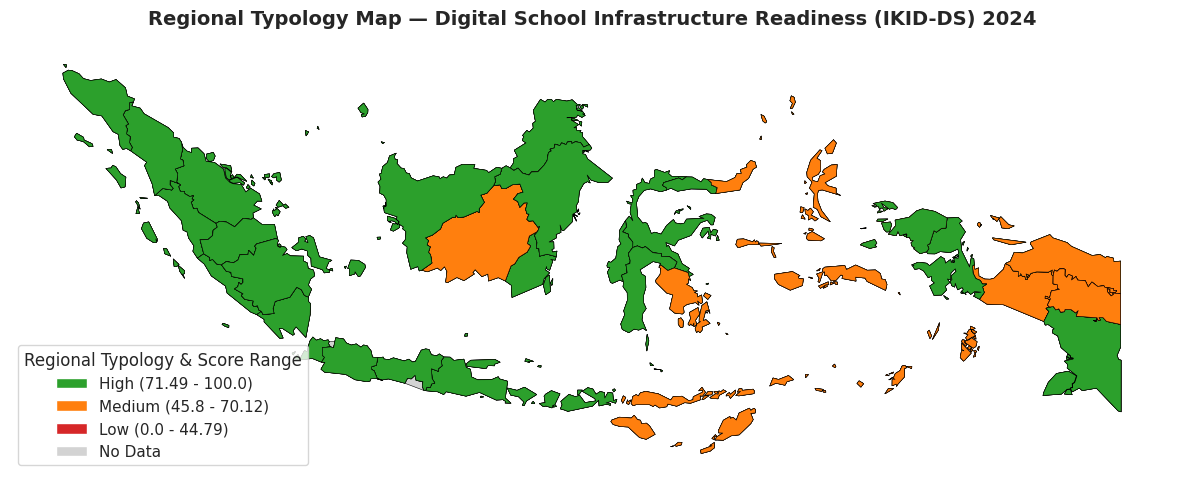

In [32]:
import requests
import pandas as pd
import numpy as np
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# 1. LOAD CLEANED DATA (already scaled & filtered)
print("=== 1. LOAD & PREPARE 2024 DATA ===")
df = pd.read_csv('data_2024_2025_cleaned.csv')

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
id_columns = ['Province', 'Year']

# Filter year 2024
df_2024 = df[df['Year'] == 2024].copy()
df_clean = df_2024[id_columns + selected_columns].dropna(subset=selected_columns).reset_index(drop=True)

print(f"Total provinces for Year 2024: {df_clean.shape[0]}")

# Min-Max Normalization (0-100)
scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_clean[selected_columns])

# PCA (Objective Weighting) & IKID-DS Composite Index
pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)
score_scaler = MinMaxScaler(feature_range=(0, 100))
df_clean['Infrastructure_Index'] = score_scaler.fit_transform(pc1_scores).flatten()

# K-Means Clustering (3 Clusters: High, Medium, Low)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster_ID'] = kmeans.fit_predict(df_clean[['Infrastructure_Index']])

cluster_means = df_clean.groupby('Cluster_ID')['Infrastructure_Index'].mean().sort_values(ascending=False)
sorted_cluster_ids = cluster_means.index
label_mapping = {
    sorted_cluster_ids[0]: 'High',
    sorted_cluster_ids[1]: 'Medium',
    sorted_cluster_ids[2]: 'Low'
}
df_clean['Readiness_Typology'] = df_clean['Cluster_ID'].map(label_mapping)

# 2. CLUSTER SUMMARY TABLE
print("\n=== 2. CLUSTER CHARACTERISTICS SUMMARY TABLE — IKID-DS 2024 ===")
cluster_table = df_clean.groupby('Readiness_Typology')['Infrastructure_Index'].agg(
    Province_Count='count',
    Min_Score='min',
    Max_Score='max',
    Mean_Score='mean'
).reindex(['High', 'Medium', 'Low']).reset_index()

cluster_table['Min_Score']  = cluster_table['Min_Score'].round(2)
cluster_table['Max_Score']  = cluster_table['Max_Score'].round(2)
cluster_table['Mean_Score'] = cluster_table['Mean_Score'].round(2)

print(cluster_table.to_string(index=False))
print("-" * 65)

# Extract score ranges for dynamic legend
range_info = {}
for _, row in cluster_table.iterrows():
    typology = row['Readiness_Typology']
    range_info[typology] = f"({row['Min_Score']} - {row['Max_Score']})"

# Prepare map DataFrame
df_map = df_clean.copy()
df_map['Join_Key'] = df_map['Province'].astype(str).str.strip().str.lower()

# 3. DOWNLOAD & LOAD GEOJSON (38 PROVINCES)
print("\n=== 3. DOWNLOADING & LOADING GEOJSON MAP (38 PROVINCES) ===")
url_geojson = "https://raw.githubusercontent.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces/main/GeoJSON/indonesia-38-provinces.geojson"
geojson_file = "indonesia_38.geojson"

response = requests.get(url_geojson)
if response.status_code == 200:
    with open(geojson_file, 'wb') as f:
        f.write(response.content)
    print("GeoJSON file (38 provinces) downloaded successfully!")

gdf = gpd.read_file(geojson_file)
map_column = 'PROVINSI'
gdf['Join_Key'] = gdf[map_column].astype(str).str.strip().str.lower()

# Name correction mapping
name_corrections = {
    'dki jakarta': 'jakarta raya',
    'di yogyakarta': 'yogyakarta'
}
df_map['Join_Key'] = df_map['Join_Key'].replace(name_corrections)

# Merge map with analysis results
gdf_merged = gdf.merge(
    df_map[['Join_Key', 'Readiness_Typology', 'Infrastructure_Index']],
    on='Join_Key', how='left'
)

# Cluster colors
color_map = {
    'High':   '#2ca02c',   # Green
    'Medium': '#ff7f0e',   # Orange
    'Low':    '#d62728'    # Red
}
gdf_merged['Color'] = gdf_merged['Readiness_Typology'].map(color_map).fillna('#d3d3d3')

# 4. PLOT MAP WITH SCORE RANGES IN LEGEND
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

gdf_merged.plot(
    ax=ax,
    color=gdf_merged['Color'],
    edgecolor='black',
    linewidth=0.4
)

plt.title('Regional Typology Map — Digital School Infrastructure Readiness (IKID-DS) 2024',
          fontsize=14, fontweight='bold', pad=15)
ax.axis('off')

# Legend labels with score ranges
legend_elements = [
    Patch(facecolor='#2ca02c', label=f"High {range_info.get('High', '')}"),
    Patch(facecolor='#ff7f0e', label=f"Medium {range_info.get('Medium', '')}"),
    Patch(facecolor='#d62728', label=f"Low {range_info.get('Low', '')}"),
    Patch(facecolor='#d3d3d3', label='No Data')
]
ax.legend(handles=legend_elements, title='Regional Typology & Score Range',
          loc='lower left', frameon=True)

plt.tight_layout()
output_map = 'ikid_ds_2024_cluster_map.png'
plt.savefig(output_map, dpi=300, bbox_inches='tight')
print(f"Cluster map with score ranges saved as: {output_map}")
plt.show()

=== 1. LOAD & PREPARE 2025 DATA ===
Total provinces for Year 2025: 152

=== 2. CLUSTER CHARACTERISTICS SUMMARY TABLE — IKID-DS 2025 ===
Readiness_Typology  Province_Count  Min_Score  Max_Score  Mean_Score
              High              60      74.83     100.00       85.63
            Medium              63      50.38      74.40       63.61
               Low              29       0.00      47.97       35.08
-----------------------------------------------------------------

=== 3. DOWNLOADING & LOADING GEOJSON MAP (38 PROVINCES) ===
GeoJSON file (38 provinces) downloaded successfully!
Cluster map for 2025 with score ranges saved as: ikid_ds_2025_cluster_map.png


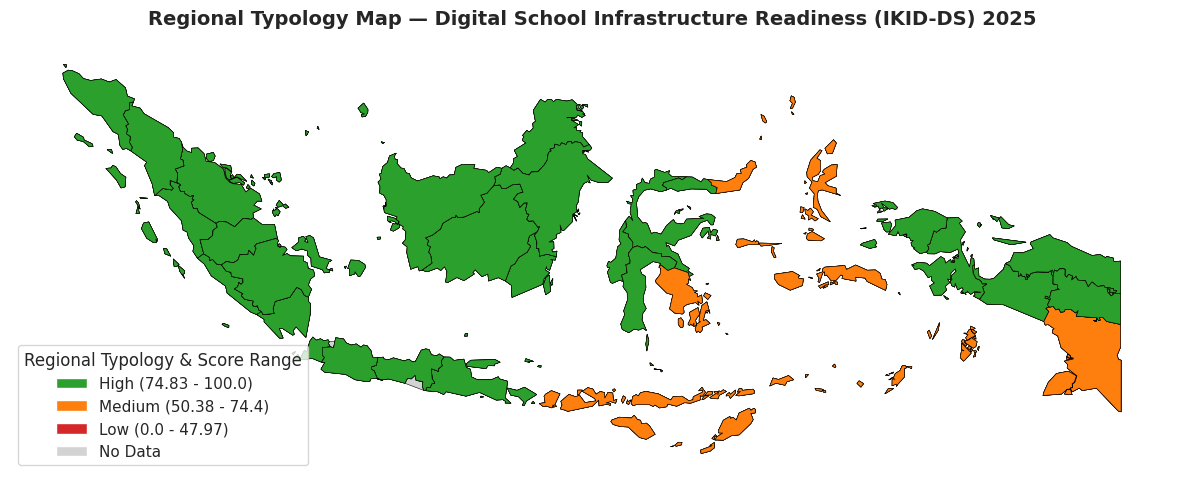

In [33]:
import requests
import pandas as pd
import numpy as np
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# 1. LOAD CLEANED DATA (already scaled & filtered)
print("=== 1. LOAD & PREPARE 2025 DATA ===")
df = pd.read_csv('data_2024_2025_cleaned.csv')

selected_columns = ['Electricity Access', 'Internet Access', 'Computer Access']
id_columns = ['Province', 'Year']

# Filter year 2025
df_2025 = df[df['Year'] == 2025].copy()
df_clean = df_2025[id_columns + selected_columns].dropna(subset=selected_columns).reset_index(drop=True)

print(f"Total provinces for Year 2025: {df_clean.shape[0]}")

# Min-Max Normalization (0-100)
scaler = MinMaxScaler(feature_range=(0, 100))
X_scaled = scaler.fit_transform(df_clean[selected_columns])

# PCA (Objective Weighting) & IKID-DS Composite Index
pca = PCA(n_components=1)
pc1_scores = pca.fit_transform(X_scaled)
score_scaler = MinMaxScaler(feature_range=(0, 100))
df_clean['Infrastructure_Index'] = score_scaler.fit_transform(pc1_scores).flatten()

# K-Means Clustering (3 Clusters: High, Medium, Low)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster_ID'] = kmeans.fit_predict(df_clean[['Infrastructure_Index']])

cluster_means = df_clean.groupby('Cluster_ID')['Infrastructure_Index'].mean().sort_values(ascending=False)
sorted_cluster_ids = cluster_means.index
label_mapping = {
    sorted_cluster_ids[0]: 'High',
    sorted_cluster_ids[1]: 'Medium',
    sorted_cluster_ids[2]: 'Low'
}
df_clean['Readiness_Typology'] = df_clean['Cluster_ID'].map(label_mapping)

# 2. CLUSTER SUMMARY TABLE
print("\n=== 2. CLUSTER CHARACTERISTICS SUMMARY TABLE — IKID-DS 2025 ===")
cluster_table = df_clean.groupby('Readiness_Typology')['Infrastructure_Index'].agg(
    Province_Count='count',
    Min_Score='min',
    Max_Score='max',
    Mean_Score='mean'
).reindex(['High', 'Medium', 'Low']).reset_index()

cluster_table['Min_Score']  = cluster_table['Min_Score'].round(2)
cluster_table['Max_Score']  = cluster_table['Max_Score'].round(2)
cluster_table['Mean_Score'] = cluster_table['Mean_Score'].round(2)

print(cluster_table.to_string(index=False))
print("-" * 65)

# Extract score ranges for dynamic legend
range_info = {}
for _, row in cluster_table.iterrows():
    typology = row['Readiness_Typology']
    range_info[typology] = f"({row['Min_Score']} - {row['Max_Score']})"

# Prepare map DataFrame
df_map = df_clean.copy()
df_map['Join_Key'] = df_map['Province'].astype(str).str.strip().str.lower()

# 3. DOWNLOAD & LOAD GEOJSON (38 PROVINCES)
print("\n=== 3. DOWNLOADING & LOADING GEOJSON MAP (38 PROVINCES) ===")
url_geojson = "https://raw.githubusercontent.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces/main/GeoJSON/indonesia-38-provinces.geojson"
geojson_file = "indonesia_38.geojson"

response = requests.get(url_geojson)
if response.status_code == 200:
    with open(geojson_file, 'wb') as f:
        f.write(response.content)
    print("GeoJSON file (38 provinces) downloaded successfully!")

gdf = gpd.read_file(geojson_file)
map_column = 'PROVINSI'
gdf['Join_Key'] = gdf[map_column].astype(str).str.strip().str.lower()

# Name correction mapping
name_corrections = {
    'dki jakarta': 'jakarta raya',
    'di yogyakarta': 'yogyakarta'
}
df_map['Join_Key'] = df_map['Join_Key'].replace(name_corrections)

# Merge map with analysis results
gdf_merged = gdf.merge(
    df_map[['Join_Key', 'Readiness_Typology', 'Infrastructure_Index']],
    on='Join_Key', how='left'
)

# Cluster colors
color_map = {
    'High':   '#2ca02c',   # Green
    'Medium': '#ff7f0e',   # Orange
    'Low':    '#d62728'    # Red
}
gdf_merged['Color'] = gdf_merged['Readiness_Typology'].map(color_map).fillna('#d3d3d3')

# 4. PLOT MAP WITH SCORE RANGES IN LEGEND
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

gdf_merged.plot(
    ax=ax,
    color=gdf_merged['Color'],
    edgecolor='black',
    linewidth=0.4
)

plt.title('Regional Typology Map — Digital School Infrastructure Readiness (IKID-DS) 2025',
          fontsize=14, fontweight='bold', pad=15)
ax.axis('off')

legend_elements = [
    Patch(facecolor='#2ca02c', label=f"High {range_info.get('High', '')}"),
    Patch(facecolor='#ff7f0e', label=f"Medium {range_info.get('Medium', '')}"),
    Patch(facecolor='#d62728', label=f"Low {range_info.get('Low', '')}"),
    Patch(facecolor='#d3d3d3', label='No Data')
]
ax.legend(handles=legend_elements, title='Regional Typology & Score Range',
          loc='lower left', frameon=True)

plt.tight_layout()
output_map = 'ikid_ds_2025_cluster_map.png'
plt.savefig(output_map, dpi=300, bbox_inches='tight')
print(f"Cluster map for 2025 with score ranges saved as: {output_map}")
plt.show()

In [34]:
%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title="IKID-DS Dashboard", layout="wide")

st.title("📊 School Digital Infrastructure Readiness Index (IKID-DS)")
st.write("Dashboard analisis kesiapan infrastruktur digital sekolah tahun 2024-2025.")

# Load Data
@st.cache_data
def load_data():
    try:
        df = pd.read_csv('normalized_ikidds.csv')
    except:
        df = pd.read_csv('data_2024_2025_cleaned.csv')
    return df

df = load_data()

# Sidebar Filter
st.sidebar.header("Filter Data")
selected_year = st.sidebar.selectbox("Pilih Tahun", sorted(df['Year'].unique()))
filtered_df = df[df['Year'] == selected_year]

# Tampilkan Data
st.subheader(f"Ringkasan Data Tahun {selected_year}")
st.dataframe(filtered_df, use_container_width=True)

# Visualisasi
if 'Computer Access' in filtered_df.columns and 'Province' in filtered_df.columns:
    st.subheader("Visualisasi Akses Komputer")
    fig = px.bar(
        filtered_df.sort_values(by='Computer Access', ascending=False).head(10),
        x='Province',
        y='Computer Access',
        title=f"Top 10 Provinsi Berdasarkan Akses Komputer ({selected_year})"
    )
    st.plotly_chart(fig, use_container_width=True)

Writing app.py


In [36]:
!pip install -q streamlit pyngrok

In [38]:
%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title="IKID-DS Dashboard", layout="wide")

st.title("📊 School Digital Infrastructure Readiness Index (IKID-DS)")
st.write("Dashboard analisis kesiapan infrastruktur digital sekolah tahun 2024-2025.")

# Load Data
@st.cache_data
def load_data():
    try:
        df = pd.read_csv('normalized_ikidds.csv')
    except:
        df = pd.read_csv('data_2024_2025_cleaned.csv')
    return df

df = load_data()

# Sidebar Filter
st.sidebar.header("Filter Data")
selected_year = st.sidebar.selectbox("Pilih Tahun", sorted(df['Year'].unique()))
filtered_df = df[df['Year'] == selected_year]

# Tampilkan Data
st.subheader(f"Ringkasan Data Tahun {selected_year}")
st.dataframe(filtered_df, use_container_width=True)

# Visualisasi
if 'Computer Access' in filtered_df.columns and 'Province' in filtered_df.columns:
    st.subheader("Visualisasi Akses Komputer")
    fig = px.bar(
        filtered_df.sort_values(by='Computer Access', ascending=False).head(10),
        x='Province',
        y='Computer Access',
        title=f"Top 10 Provinsi Berdasarkan Akses Komputer ({selected_year})"
    )
    st.plotly_chart(fig, use_container_width=True)

Overwriting app.py


In [40]:
from pyngrok import ngrok
import subprocess
import time

# 1. Masukkan Auth Token ngrok Anda di sini
ngrok.set_auth_token("ISI_AUTHTOKEN_ANDA_DISINI")

# 2. Matikan sisa proses ngrok sebelumnya jika ada (biar tidak bentrok)
ngrok.kill()

# 3. Jalankan Streamlit di background (port 8501)
subprocess.Popen(["streamlit", "run", "app.py", "--server.port=8501"])
time.sleep(3) # Tunggu server siap

# 4. Buka public URL dengan Pyngrok
public_url = ngrok.connect(8501)

print(f"🚀 Streamlit App Anda sudah online di link berikut:")
print(public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-28T03:37:36+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-28T03:37:36+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: The authtoken you specified does not look like a proper ngrok authtoken.\nInstructions to install your authtoken are on your ngrok dashboard:\nhttps://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_105\r\n.